# 04. Проверка финального прогноза и графики для презентации

**Часть 1.** Sanity-check `predictions.csv` (CatBoost): сравнение с историей, матчи в продаже,
заполняемость зон, флаги. Прогноз здесь только проверяется, ничего не исправляется.

**Часть 2.** Семь графиков для слайдов → `reports/figures/` (PNG, 150 dpi).

**Часть 3.** Значимость выигрыша: бутстрэп по матчам.

**Часть 4.** Неопределённость и бизнес-метрики: интервалы 10–90% по остаткам валидации (по строкам — ориентир; по матчам — сумма зональных границ; покрытие leave-one-fold-out) → `submissions/prediction_intervals*.csv`, график `07_test_intervals.png`; метрики на матч целиком для трёх моделей.

Прогоны `evaluate` для трёх моделей кэшируются в `reports/cache/`. Кэш привязан к хэшу
`src/*.py` и списку фолдов: если модель или валидация поменялись, `evaluate` пересчитается сам.
Принудительный пересчёт: `FORCE = True`.

## 0. Настройки

In [1]:
import hashlib
import json
import sys
import time
from pathlib import Path

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from src.baseline import smart_baseline_predict, zone_mean_predict
from src.data import build_table, load_daily_sales
from src.model import catboost_predict
from src.validation import FOLDS, KEY, evaluate, rmse

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
FORCE = False  # True — пересчитать evaluate, игнорируя кэш

FIG_DIR = ROOT / "reports" / "figures"
CACHE_DIR = ROOT / "reports" / "cache"
FIG_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
T0 = time.perf_counter()

In [2]:
# Оформление под слайды: крупный шрифт, без лишней рамки, светлая сетка.
# Цвета моделей (фиксированы во всех графиках) — первые три слота проверенной
# категориальной палитры; зоны — порядковая шкала одного оттенка (зона 1 самая тёмная).
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 13, "axes.titlesize": 16, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 13, "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#2b2b29", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#a3a29c"

MODEL_NAMES = {"zone_mean": "Среднее по зоне (baseline)", "smart": "Умный baseline", "catboost": "CatBoost"}
MODEL_COLORS = {"catboost": "#2a78d6", "smart": "#eb6834", "zone_mean": "#1baf7a"}
ZONE_COLORS = dict(zip(range(1, 9), ["#104281", "#184f95", "#1c5cab", "#256abf",
                                     "#2a78d6", "#3987e5", "#5598e7", "#86b6ef"]))


def ru(v, nd=1):
    # Число в русской записи: пробел между тысячами, десятичная запятая
    return f"{v:,.{nd}f}".replace(",", " ").replace(".", ",")


def save(fig, name):
    path = FIG_DIR / name
    fig.savefig(path, facecolor="white")
    print("сохранено:", path.relative_to(ROOT))

### Прогоны evaluate с кэшем

В кэше хранится только `EvalResult.preds` (фолд, матч, зона, факт, прогноз). RMSE общий,
по фолдам и по зонам пересчитываются из него теми же формулами, что в `src.validation.evaluate`.
Ключ кэша — хэш исходников `src/` (переводы строк нормализованы, чтобы хэш совпадал на Windows
и Linux) и список фолдов.

In [3]:
MODELS = {"zone_mean": zone_mean_predict, "smart": smart_baseline_predict, "catboost": catboost_predict}
SRC_FILES = ["data.py", "validation.py", "baseline.py", "model.py"]


def code_hash():
    h = hashlib.sha256()
    for name in SRC_FILES:
        h.update((ROOT / "src" / name).read_bytes().replace(b"\r\n", b"\n"))
    h.update(json.dumps(list(FOLDS)).encode())
    return h.hexdigest()[:16]


def cached_preds(name, fn, force=FORCE):
    csv, meta = CACHE_DIR / f"eval_{name}.csv", CACHE_DIR / f"eval_{name}.json"
    key = code_hash()
    if not force and csv.exists() and meta.exists() and json.loads(meta.read_text())["hash"] == key:
        preds = pd.read_csv(csv, encoding="utf-8", dtype={"fold": str})
        print(f"{name:<10} из кэша")
        return preds
    t = time.perf_counter()
    preds = evaluate(fn).preds
    preds.to_csv(csv, index=False, encoding="utf-8")
    meta.write_text(json.dumps({"hash": key, "folds": list(FOLDS)}, ensure_ascii=False, indent=1))
    print(f"{name:<10} посчитано за {time.perf_counter() - t:.0f} с")
    return preds


preds = {name: cached_preds(name, fn) for name, fn in MODELS.items()}
FOLD_LABELS = list(dict.fromkeys(preds["catboost"]["fold"]))

zone_mean  из кэша
smart      из кэша
catboost   из кэша


In [4]:
def rmse_by(p, by):
    return p.groupby(by, sort=False)[["y_true", "y_pred"]].apply(lambda g: rmse(g["y_true"], g["y_pred"]))


overall = pd.Series({n: rmse(p["y_true"], p["y_pred"]) for n, p in preds.items()})
by_fold = pd.DataFrame({n: rmse_by(p, "fold") for n, p in preds.items()}).loc[FOLD_LABELS]
by_fold.loc["все фолды"] = overall
by_zone = pd.DataFrame({n: rmse_by(p, "zone") for n, p in preds.items()}).sort_index()
by_status = pd.DataFrame({n: rmse_by(p, "in_sale") for n, p in preds.items()})
by_status.index = by_status.index.map({True: "в продаже на as_of", False: "ещё не в продаже"})

# Эталон из solution.ipynb: если не сходится — валидация или baseline изменились
assert abs(overall["zone_mean"] - 141.0) < 0.05, overall["zone_mean"]
assert abs(overall["smart"] - 135.2) < 0.05, overall["smart"]

print("RMSE по фолдам:")
display(by_fold.round(1))
print("RMSE по зонам:")
display(by_zone.round(1))
print("RMSE по статусу продаж:")
display(by_status.round(1))

RMSE по фолдам:


,zone_mean,smart,catboost
fold,,,
2023-12-15,172.2,172.2,163.3
2024-11-25,103.0,79.1,83.1
2025-09-20,147.2,148.5,121.6
все фолды,141.0,135.2,124.7


RMSE по зонам:


,zone_mean,smart,catboost
zone,,,
1,41.6,36.8,26.2
2,38.4,28.9,26.2
3,63.3,59.1,53.1
4,164.3,139.0,119.6
5,109.4,119.5,117.5
6,257.0,225.7,202.6
7,208.5,228.4,218.8
8,58.8,62.2,55.5


RMSE по статусу продаж:


,zone_mean,smart,catboost
in_sale,,,
в продаже на as_of,119.3,110.9,105.8
ещё не в продаже,149.5,144.5,132.0


## Часть 1. Sanity-check `predictions.csv`

Таблица `test` — 17 test-матчей × 8 зон: прогноз, уже проданное на 15.12.2025 (`sold_as_of`),
capacity. История `hist` — 85 сыгранных train-матчей с фактическим итогом. Это проверка
готового прогноза, а не признаки модели, поэтому история берётся целиком (все матчи до 15.12.2025).

In [5]:
df = build_table()
sub = pd.read_csv(ROOT / "predictions.csv", encoding="utf-8")
assert len(sub) == 136 and sub["tickets_total"].notna().all()

test = sub.merge(df[df["is_test"] == 1], on=KEY, how="left", validate="one_to_one", suffixes=("", "_y"))
test = test.drop(columns="tickets_total_y").rename(columns={"tickets_total": "pred"})
hist = df[df["tickets_total"].notna()].copy()
hist["fill"] = hist["tickets_total"] / hist["capacity"]
test["fill"] = test["pred"] / test["capacity"]

match_cols = ["match_id", "match_date", "season", "month", "weekday", "opponent"]
hist_m = hist.groupby(match_cols, as_index=False).agg(total=("tickets_total", "sum"), capacity=("capacity", "sum"))
test_m = test.groupby(match_cols + ["days_to_match", "sales_started"], as_index=False).agg(
    pred=("pred", "sum"), sold=("sold_as_of", "sum"), capacity=("capacity", "sum"))
print(f"история: {len(hist_m)} матчей, test: {len(test_m)} матчей, сумма прогноза {test_m['pred'].sum()}")

история: 85 матчей, test: 17 матчей, сумма прогноза 85631


### 1.1. Сумма прогноза по матчу против истории

- **сезон 2025/26** — 17 уже сыгранных матчей текущего сезона (сен–дек 2025);
- **тот же месяц, прошлые сезоны** — матчи 2023/24 и 2024/25 в том же календарном месяце.

`к_сезону` — прогноз / среднее сезона; `z_сезон` — отклонение от среднего сезона в стандартных
отклонениях матчей сезона.

In [6]:
cur = hist_m[hist_m["season"] == "2025/26"]["total"]
prev = hist_m[hist_m["season"] != "2025/26"].groupby("month")["total"].agg(["mean", "min", "max", "size"])

t1 = test_m[["match_id", "match_date", "opponent", "weekday", "sales_started", "sold", "pred"]].copy()
t1["сезон_ср"], t1["сезон_мин"], t1["сезон_макс"] = cur.mean(), cur.min(), cur.max()
t1 = t1.assign(month=test_m["month"]).join(prev.add_prefix("месяц_"), on="month")
t1["к_сезону"] = t1["pred"] / cur.mean()
t1["z_сезон"] = (t1["pred"] - cur.mean()) / cur.std()
t1["к_месяцу"] = t1["pred"] / t1["месяц_mean"]

print(f"Сезон 2025/26 (сыграно {len(cur)}): среднее {cur.mean():.0f}, мин {cur.min():.0f}, "
      f"макс {cur.max():.0f}, std {cur.std():.0f}")
print("Прошлые сезоны по месяцам:")
display(prev.round(0).astype(int))
t1_show = t1.assign(match_date=t1["match_date"].dt.strftime("%d.%m.%Y"))
display(t1_show.round({"сезон_ср": 0, "месяц_mean": 0, "к_сезону": 2, "z_сезон": 2, "к_месяцу": 2}))

Сезон 2025/26 (сыграно 17): среднее 4797, мин 3560, макс 5691, std 626
Прошлые сезоны по месяцам:


,mean,min,max,size
month,,,,
1,4889,4443,5270,11
2,4936,4455,5301,10
3,4996,4991,5002,2
9,4289,3395,5097,12
10,4845,4193,5323,13
11,4534,3221,5490,9
12,4297,3641,5096,11


,match_id,match_date,opponent,weekday,sales_started,sold,pred,сезон_ср,сезон_мин,сезон_макс,month,месяц_mean,месяц_min,месяц_max,месяц_size,к_сезону,z_сезон,к_месяцу
0,M086,24.12.2025,Нефтехимик,3,1,3152,4757,4797.0,3560.0,5691.0,12,4297.0,3641.0,5096.0,11,0.99,-0.06,1.11
1,M087,26.12.2025,Металлург Мг,5,1,4056,5348,4797.0,3560.0,5691.0,12,4297.0,3641.0,5096.0,11,1.11,0.88,1.24
2,M088,28.12.2025,Лада,7,1,3267,4663,4797.0,3560.0,5691.0,12,4297.0,3641.0,5096.0,11,0.97,-0.21,1.09
3,M089,30.12.2025,Барыс,2,1,3845,5158,4797.0,3560.0,5691.0,12,4297.0,3641.0,5096.0,11,1.08,0.58,1.20
4,M090,13.01.2026,Салават Юлаев,2,1,935,5231,4797.0,3560.0,5691.0,1,4889.0,4443.0,5270.0,11,1.09,0.69,1.07
5,M091,15.01.2026,ЦСКА,4,1,851,5141,4797.0,3560.0,5691.0,1,4889.0,4443.0,5270.0,11,1.07,0.55,1.05
6,M092,26.01.2026,Адмирал,1,0,0,4945,4797.0,3560.0,5691.0,1,4889.0,4443.0,5270.0,11,1.03,0.24,1.01
7,M093,29.01.2026,Трактор,4,0,0,5041,4797.0,3560.0,5691.0,1,4889.0,4443.0,5270.0,11,1.05,0.39,1.03
8,M094,05.02.2026,Автомобилист,4,0,0,5261,4797.0,3560.0,5691.0,2,4936.0,4455.0,5301.0,10,1.10,0.74,1.07
9,M095,15.02.2026,Трактор,7,0,0,4846,4797.0,3560.0,5691.0,2,4936.0,4455.0,5301.0,10,1.01,0.08,0.98


### 1.2. Матчи в продаже: уже продано vs прогноз итога

Для каждого из 6 матчей в продаже: какая доля прогноза итога **ещё не продана** на 15.12.2025.
Сравниваем с историей: на сыгранных матчах при том же `days_to_match = d` (за d дней до матча)
ещё не было продано `продажи с days_before ≤ d / итог` (ровно та граница, что у `sold_as_of`
в `build_table`). Берём только исторические матчи, на которые к этому моменту продажи уже
были открыты (окно продаж > d). Медиана и коридор p10–p90 по матчам.

`итог_по_кривой` — какой итог получился бы, если остаток продаётся как у медианного матча:
`sold / (1 − медиана доли остатка)`.

In [7]:
daily = load_daily_sales()  # все продажи до 15.12.2025
daily = daily[daily["match_id"].isin(hist["match_id"])]
window = (df.drop_duplicates("match_id").set_index("match_id")
          .eval("match_date - sales_open").dt.days)


def remaining_share(d, level):
    # Доля итога, проданная при days_before <= d, по сыгранным матчам с окном продаж > d.
    ids = window[(window > d) & window.index.isin(hist["match_id"])].index
    dd = daily[daily["match_id"].isin(ids)]
    tot = dd.groupby(level)["tickets"].sum()
    late = dd[dd["days_before"] <= d].groupby(level)["tickets"].sum().reindex(tot.index, fill_value=0)
    return (late / tot)[tot > 0]


in_sale = test_m[test_m["sales_started"] == 1].copy()
rows = []
for r in in_sale.itertuples():
    sh = remaining_share(r.days_to_match, "match_id")
    rows.append({"match_id": r.match_id, "n_ист": len(sh), "ист_p10": sh.quantile(0.1),
                 "ист_медиана": sh.median(), "ист_p90": sh.quantile(0.9)})
t2 = in_sale[["match_id", "match_date", "opponent", "days_to_match", "capacity", "sold", "pred"]].merge(pd.DataFrame(rows))
t2["осталось_прогноз"] = 1 - t2["sold"] / t2["pred"]
t2["вне_p10_p90"] = ~t2["осталось_прогноз"].between(t2["ист_p10"], t2["ист_p90"])
# Темп: продано сейчас / сколько к этому дню обычно продано у среднего матча сезона
t2["темп"] = t2["sold"] / (cur.mean() * (1 - t2["ист_медиана"]))
t2["итог_по_кривой"] = (t2["sold"] / (1 - t2["ист_медиана"])).round()
t2["заполн_продано"] = t2["sold"] / t2["capacity"]
t2["заполн_прогноз"] = t2["pred"] / t2["capacity"]
t2["заполн_по_кривой"] = t2["итог_по_кривой"] / t2["capacity"]
hist_fill_max = (hist_m["total"] / hist_m["capacity"]).max()
print(f"Макс. заполняемость матча в истории (сумма зон): {hist_fill_max:.0%}")
display(t2.assign(match_date=t2["match_date"].dt.strftime("%d.%m.%Y")).round(2))

Макс. заполняемость матча в истории (сумма зон): 81%


,match_id,match_date,opponent,days_to_match,capacity,sold,pred,n_ист,ист_p10,ист_медиана,ист_p90,осталось_прогноз,вне_p10_p90,темп,итог_по_кривой,заполн_продано,заполн_прогноз,заполн_по_кривой
0,M086,24.12.2025,Нефтехимик,9,6916,3152,4757,85,0.15,0.44,0.69,0.34,False,1.17,5597.0,0.46,0.69,0.81
1,M087,26.12.2025,Металлург Мг,11,6916,4056,5348,84,0.19,0.50,0.72,0.24,False,1.69,8125.0,0.59,0.77,1.17
2,M088,28.12.2025,Лада,13,6368,3267,4663,84,0.24,0.58,0.79,0.30,False,1.64,7846.0,0.51,0.73,1.23
3,M089,30.12.2025,Барыс,15,6916,3845,5158,81,0.27,0.62,0.85,0.25,True,2.13,10228.0,0.56,0.75,1.48
4,M090,13.01.2026,Салават Юлаев,29,7065,935,5231,52,0.60,0.83,0.93,0.82,False,1.15,5515.0,0.13,0.74,0.78
5,M091,15.01.2026,ЦСКА,31,7065,851,5141,43,0.61,0.84,0.94,0.83,False,1.12,5376.0,0.12,0.73,0.76


In [8]:
# То же по зонам: прогнозная доля остатка vs историческая медиана той же зоны при том же d
zrows = []
for r in in_sale.itertuples():
    sh = remaining_share(r.days_to_match, ["match_id", "zone"]).groupby("zone").median()
    z = test[test["match_id"] == r.match_id].set_index("zone")
    zrows.append(pd.DataFrame({"match_id": r.match_id, "zone": z.index,
                               "осталось_прогноз": 1 - z["sold_as_of"] / z["pred"],
                               "ист_медиана": sh.reindex(z.index).to_numpy()}))
t2z = pd.concat(zrows, ignore_index=True)
t2z["разница"] = t2z["осталось_прогноз"] - t2z["ист_медиана"]
print("Доля «осталось продать»: прогноз − историческая медиана, по зонам (п.п. доли)")
display(t2z.pivot(index="match_id", columns="zone", values="разница").round(2))

Доля «осталось продать»: прогноз − историческая медиана, по зонам (п.п. доли)


zone,1,2,3,4,5,6,7,8
match_id,,,,,,,,
M086,-0.08,0.03,0.01,-0.10,-0.03,-0.07,-0.16,-0.26
M087,-0.22,-0.13,-0.07,-0.26,-0.09,-0.38,-0.39,-0.51
M088,-0.13,-0.21,-0.03,-0.37,-0.19,-0.36,-0.32,-0.55
M089,-0.25,-0.31,-0.16,-0.42,-0.28,-0.47,-0.46,-0.56
M090,0.11,-0.10,-0.01,-0.03,0.03,-0.02,-0.03,-0.07
M091,0.00,-0.04,0.02,0.01,0.01,-0.05,-0.00,-0.04


### 1.3. Заполняемость прогноза по зонам

Заполняемость = прогноз / capacity (capacity = seats − season_tickets). Сравниваем с фактической
заполняемостью сыгранных матчей той же зоны. `на_capacity` — строки, где прогноз упёрся в потолок
(сработал клиппинг в `postprocess`); `выше_ист_макс` — строки выше исторического максимума зоны.

In [9]:
hz = hist.groupby("zone")["fill"].agg(ист_медиана="median", ист_p95=lambda s: s.quantile(0.95), ист_макс="max")
tz = test.groupby("zone").agg(прогноз_мин=("fill", "min"), прогноз_медиана=("fill", "median"),
                              прогноз_макс=("fill", "max"))
t3 = hz.join(tz)
zmax, zmin = test["zone"].map(hz["ист_макс"]), test["zone"].map(hist.groupby("zone")["fill"].min())
t3["выше_ист_макс"] = (test["fill"] > zmax).groupby(test["zone"]).sum()
t3["ниже_ист_мин"] = (test["fill"] < zmin).groupby(test["zone"]).sum()
t3["на_capacity"] = (test["pred"] == test["capacity"]).groupby(test["zone"]).sum()
display(t3.round(2))
assert (test["pred"] >= test["sold_as_of"]).all() and (test["pred"] <= test["capacity"]).all()
print("OK: sold_as_of <= прогноз <= capacity во всех 136 строках")

,ист_медиана,ист_p95,ист_макс,прогноз_мин,прогноз_медиана,прогноз_макс,выше_ист_макс,ниже_ист_мин,на_capacity
zone,,,,,,,,,
1,0.79,0.82,0.84,0.78,0.81,0.85,1,0,0
2,0.81,0.87,0.90,0.76,0.78,0.82,0,0,0
3,0.63,0.70,0.72,0.58,0.63,0.65,0,0,0
4,0.82,0.85,0.88,0.74,0.81,0.85,0,0,0
5,0.80,0.86,0.87,0.72,0.78,0.85,0,0,0
6,0.31,0.75,0.77,0.54,0.64,0.75,0,0,0
7,0.66,0.88,0.93,0.64,0.69,0.78,0,0,0
8,0.84,0.93,0.97,0.81,0.85,0.90,0,0,0


OK: sold_as_of <= прогноз <= capacity во всех 136 строках


### 1.4. Флаги: где прогноз выбивается из истории сильнее всего

Правила флагов (любое одно → матч в таблице):
- **сумма вне сезона** — прогноз суммы матча ниже минимума или выше максимума сыгранных матчей 2025/26;
- **|z| > 2** — сумма дальше двух стандартных отклонений от среднего сезона;
- **вне месяца** — сумма вне [мин, макс] того же месяца прошлых сезонов (если в месяце ≥ 5 матчей;
  в марте прошлых сезонов их 2, сравнение не информативно);
- **темп продаж** — для матчей в продаже продано в 1,5+ раза больше (или в 1,5+ раза меньше), чем
  обычно к этому дню; итог для таких матчей предсказывать труднее всего;
- **остаток вне p10–p90** — для матчей в продаже доля «осталось продать» вне исторического коридора;
- **зона выше макс.** — заполняемость зоны выше исторического максимума этой зоны.

**Почему «темп» и «остаток вне p10–p90» срабатывают на новогодних матчах.** Оба критерия сравнивают матч
с типичной кривой продаж по всем сыгранным матчам: обычный матч за 11–15 дней до игры продал 38–50% итога.
Новогодние матчи распродаются раньше: в прошлые Новые годы к той же дате было продано 84–94% итога
(кроме M055 — 56–69%, раздел 1.5). Поэтому флаг на них — ожидаемое следствие ранней кривой, а не признак
ошибки модели, и досчитывать остаток по типичной кривой для них нельзя. Критерий оставляем: он верно отмечает,
что матч не похож на типичный; с прошлыми новогодними матчами его сравнивает раздел 1.5.

Таблица отсортирована по числу причин, затем по |log(прогноз / среднее сезона)|. Ничего не исправляем, только фиксируем.

In [10]:
WD = {1: "пн", 2: "вт", 3: "ср", 4: "чт", 5: "пт", 6: "сб", 7: "вс"}
over = test.join(hz["ист_макс"], on="zone")
over = over[over["fill"] > over["ист_макс"]]
t2i = t2.set_index("match_id")
MIN_MONTH, PACE = 5, 1.5


def reasons(r):
    out = []
    if r["pred"] < r["сезон_мин"]:
        out.append(f"сумма {r['pred']:.0f} < мин. сезона {r['сезон_мин']:.0f}")
    if r["pred"] > r["сезон_макс"]:
        out.append(f"сумма {r['pred']:.0f} > макс. сезона {r['сезон_макс']:.0f}")
    if abs(r["z_сезон"]) > 2:
        out.append(f"z = {r['z_сезон']:+.1f}")
    if r["месяц_size"] >= MIN_MONTH and not r["месяц_min"] <= r["pred"] <= r["месяц_max"]:
        out.append(f"вне месяца прошлых сезонов [{r['месяц_min']:.0f}; {r['месяц_max']:.0f}]")
    if r["match_id"] in t2i.index and t2i.loc[r["match_id"], "вне_p10_p90"]:
        q = t2i.loc[r["match_id"]]
        out.append(f"осталось продать {q['осталось_прогноз']:.0%} при истор. "
                   f"{q['ист_p10']:.0%}–{q['ист_p90']:.0%} (медиана {q['ист_медиана']:.0%})")
    if r["match_id"] in t2i.index and not 1 / PACE <= t2i.loc[r["match_id"], "темп"] <= PACE:
        q = t2i.loc[r["match_id"]]
        out.append(f"темп продаж ×{q['темп']:.1f} к обычному: продано {q['заполн_продано']:.0%} мест, "
                   f"по кривой вышло бы {q['заполн_по_кривой']:.0%}, прогноз {q['заполн_прогноз']:.0%} "
                   f"(истор. макс. {hist_fill_max:.0%})")
    z = over[over["match_id"] == r["match_id"]]
    if len(z):
        out.append("зоны выше истор. макс. заполняемости: " + ", ".join(
            f"{int(a.zone)} ({a.fill:.0%} > {a.ист_макс:.0%})" for a in z.itertuples()))
    return "; ".join(out)


flags = t1.assign(причины=t1.apply(reasons, axis=1), откл=np.log(t1["к_сезону"]).abs())
flags["n_причин"] = flags["причины"].str.count("; ") + (flags["причины"] != "")
flags = flags.sort_values(["n_причин", "откл"], ascending=False)
flag_table = (flags[flags["причины"] != ""]
              .assign(дата=lambda x: x["match_date"].dt.strftime("%d.%m"), день=lambda x: x["weekday"].map(WD),
                      в_продаже=lambda x: np.where(x["sales_started"] == 1, "да", "нет"))
              [["match_id", "дата", "день", "opponent", "в_продаже", "pred", "к_сезону", "z_сезон", "причины"]]
              .rename(columns={"opponent": "соперник", "pred": "прогноз"}))
print(f"Флагов: {len(flag_table)} матчей из {len(t1)}")
with pd.option_context("display.max_colwidth", 200):
    display(flag_table.round(2))

Флагов: 5 матчей из 17


,match_id,дата,день,соперник,в_продаже,прогноз,к_сезону,z_сезон,причины
3,M089,30.12,вт,Барыс,да,5158,1.08,0.58,"вне месяца прошлых сезонов [3641; 5096]; осталось продать 25% при истор. 27%–85% (медиана 62%); темп продаж ×2.1 к обычному: продано 56% мест, по кривой вышло бы 148%, прогноз 75% (истор. макс. 81%)"
1,M087,26.12,пт,Металлург Мг,да,5348,1.11,0.88,"вне месяца прошлых сезонов [3641; 5096]; темп продаж ×1.7 к обычному: продано 59% мест, по кривой вышло бы 117%, прогноз 77% (истор. макс. 81%)"
13,M099,27.02,пт,Металлург Мг,нет,5378,1.12,0.93,вне месяца прошлых сезонов [4455; 5301]
14,M100,09.03,пн,Сибирь,нет,4643,0.97,-0.25,зоны выше истор. макс. заполняемости: 1 (85% > 84%)
2,M088,28.12,вс,Лада,да,4663,0.97,-0.21,"темп продаж ×1.6 к обычному: продано 51% мест, по кривой вышло бы 123%, прогноз 73% (истор. макс. 81%)"


**Пояснение к флагам** (на прогнозе от `src/model.py` текущей версии; ничего не исправлено):

- **M087, M088, M089 (26–30.12) — ранний спрос, как в прошлые Новые годы.** К 15.12 на них продано 51–59% мест,
  в 1,6–2,1 раза больше, чем у обычного матча за 11–15 дней до игры, поэтому срабатывают флаги «темп»
  и (у M089, 25% осталось продать) «остаток вне p10–p90». Досчитать остаток по типичной кривой нельзя: вышло бы
  117–148% вместимости. У новогодних матчей своя кривая: в прошлые Новые годы к той же дате было продано
  84–94% итога (кроме M055), а итог составил 66–72% мест (раздел 1.5). Спрос приходит раньше, но не больше.
  Флаг «вне месяца» у M087 и M089 — следствие того же: прогноз выше всех декабрьских матчей прошлых сезонов.
- **В этом году к той же дате продано меньше, чем в прошлые Новые годы:** 51–59% мест против 58–68% у 4 матчей
  из 5 (у M055 — 39–48%). По новогодней кривой итог был бы 56–63% (медиана по 5 матчам), модель ставит 73–77% —
  она учитывает, что сезон 2025/26 в целом заполненнее (средняя заполняемость матча 70% против 66% и 63%
  в прошлых сезонах). Аналогия построена на 5 матчах, поэтому риск отклонения в обе стороны, скорее в сторону
  переоценки; в другую сторону — M055: по его кривой итог вышел бы 81–99%. Прогноз модели не правили, чтобы
  не подгонять под 5 матчей.
- **M086 (24.12, Нефтехимик)** тоже в новогоднем окне, но без флагов: продано 46% мест, по новогодней кривой
  итог 49%, модель ставит 69%. Картина та же, что у M087–M089.
- **M099 (27.02, Металлург Мг)** — 5,4 тыс., чуть выше максимума февраля прошлых сезонов (5,3 тыс.), но
  внутри диапазона текущего сезона (макс. 5,7 тыс.). Это пятница, а матчи с Металлургом в истории в среднем
  на 5% выше среднего сезона; максимум текущего сезона (M079, 5,7 тыс.) тоже был с ним. Флаг слабый.
- **M100 (09.03, Сибирь)** — зона 1 на 85% при историческом максимуме 84%: превышение на 1 п.п., в пределах шума.
- По сумме матча ни один прогноз не выходит за [мин, макс] сыгранных матчей сезона (|z| ≤ 0,93),
  заполняемость ни в одной зоне не упирается в capacity: нереальных значений нет.

### 1.5. Прошлые новогодние матчи: продано к той же дате и итог

Флаги «темп» и «остаток вне p10–p90» сравнивают матч со **всеми** сыгранными матчами. Новогодние матчи
продаются по своей кривой, поэтому сравниваем их ещё и с прошлыми новогодними.

- Новогоднее окно задано правилом, а не списком матчей: `NY_WINDOW` — с 24.12 по 08.01 включительно.
  В прошлых сезонах в него попадают 5 матчей, в test — матчи в продаже из того же окна.
- `мест_к_dN` — доля свободных мест (capacity), проданная раньше чем за N дней до матча
  (`days_before > N`, та же граница, что у `sold_as_of`); N — `days_to_match` test-матчей окна.
  `итога_к_dN` — та же продажа как доля итога матча.
- `по_НГ_кривой` — итог test-матча, если остаток продаётся как у прошлого новогоднего матча:
  `sold / итога_к_dN`, в долях capacity. Отдельно — по каждому прошлому матчу и медиана по пяти.


In [11]:
# Новогоднее окно: ММДД начала и конца, включительно (переходит через Новый год)
NY_WINDOW = (1224, 108)


def in_ny_window(dates):
    md = dates.dt.month * 100 + dates.dt.day
    return (md >= NY_WINDOW[0]) | (md <= NY_WINDOW[1])


ny_past = hist_m[in_ny_window(hist_m["match_date"])].set_index("match_id")
ny_test = t2[in_ny_window(t2["match_date"])].set_index("match_id")
ny_days = sorted(ny_test["days_to_match"].unique())
assert (window.reindex(ny_past.index) > max(ny_days)).all()  # к этим датам продажи уже были открыты

dd = daily[daily["match_id"].isin(ny_past.index)]
early = (pd.DataFrame({d: dd[dd["days_before"] > d].groupby("match_id")["tickets"].sum() for d in ny_days})
         .reindex(ny_past.index, fill_value=0))
past_tab = pd.DataFrame({"дата": ny_past["match_date"].dt.strftime("%d.%m.%Y"), "соперник": ny_past["opponent"],
                         "окно_продаж": window.reindex(ny_past.index)})
for d in ny_days:
    past_tab[f"мест_к_d{d}"] = early[d] / ny_past["capacity"]
for d in ny_days:
    past_tab[f"итога_к_d{d}"] = early[d] / ny_past["total"]
past_tab["итог_заполн"] = ny_past["total"] / ny_past["capacity"]
print(f"Прошлые новогодние матчи ({len(ny_past)}): продано к d дням до матча и итог, доли")
display(past_tab.round(2))

# Итог test-матча по кривой каждого прошлого новогоднего матча, в долях capacity
ny_curve = pd.DataFrame({mid: r["sold"] / early[r["days_to_match"]] * ny_past["total"] / r["capacity"]
                         for mid, r in ny_test.iterrows()}).T
ny_tab = pd.DataFrame({"дата": ny_test["match_date"].dt.strftime("%d.%m.%Y"), "соперник": ny_test["opponent"],
                       "d": ny_test["days_to_match"], "продано_мест": ny_test["заполн_продано"],
                       "прошлые_НГ_к_d_мин": [past_tab[f"мест_к_d{d}"].min() for d in ny_test["days_to_match"]],
                       "прошлые_НГ_к_d_макс": [past_tab[f"мест_к_d{d}"].max() for d in ny_test["days_to_match"]],
                       "по_обычной_кривой": ny_test["заполн_по_кривой"],
                       "по_НГ_кривой_медиана": ny_curve.median(axis=1),
                       "прогноз_модели": ny_test["заполн_прогноз"]})
print("Test-матчи в новогоднем окне: заполняемость, доли capacity")
display(ny_tab.round(2))
print("Итог по кривой каждого прошлого новогоднего матча:")
display(ny_curve.round(2))

season_fill = (hist_m["total"] / hist_m["capacity"]).groupby(hist_m["season"]).mean()
print("Средняя заполняемость матча по сезонам:", season_fill.round(3).to_dict())


Прошлые новогодние матчи (5): продано к d дням до матча и итог, доли


,дата,соперник,окно_продаж,мест_к_d9,мест_к_d11,мест_к_d13,мест_к_d15,итога_к_d9,итога_к_d11,итога_к_d13,итога_к_d15,итог_заполн
match_id,,,,,,,,,,,,
M023,24.12.2023,Металлург Мг,23,0.64,0.62,0.61,0.58,0.92,0.89,0.88,0.84,0.70
M024,03.01.2024,Салават Юлаев,33,0.68,0.68,0.66,0.64,0.95,0.94,0.92,0.89,0.72
M025,06.01.2024,Лада,36,0.66,0.66,0.64,0.62,0.94,0.93,0.91,0.88,0.71
M055,28.12.2024,Лада,40,0.53,0.48,0.44,0.39,0.76,0.69,0.63,0.56,0.70
M056,30.12.2024,Металлург Мг,42,0.62,0.62,0.61,0.60,0.94,0.93,0.93,0.91,0.66


Test-матчи в новогоднем окне: заполняемость, доли capacity


,дата,соперник,d,продано_мест,прошлые_НГ_к_d_мин,прошлые_НГ_к_d_макс,по_обычной_кривой,по_НГ_кривой_медиана,прогноз_модели
M086,24.12.2025,Нефтехимик,9,0.46,0.53,0.68,0.81,0.49,0.69
M087,26.12.2025,Металлург Мг,11,0.59,0.48,0.68,1.17,0.63,0.77
M088,28.12.2025,Лада,13,0.51,0.44,0.66,1.23,0.56,0.73
M089,30.12.2025,Барыс,15,0.56,0.39,0.64,1.48,0.63,0.75


Итог по кривой каждого прошлого новогоднего матча:


match_id,M023,M024,M025,M055,M056
M086,0.50,0.48,0.49,0.60,0.48
M087,0.66,0.62,0.63,0.85,0.63
M088,0.58,0.56,0.56,0.81,0.55
M089,0.66,0.62,0.63,0.99,0.61


Средняя заполняемость матча по сезонам: {'2023/24': 0.657, '2024/25': 0.632, '2025/26': 0.7}


## Часть 2. Графики для слайдов

### 2.0. Заполняемость по зонам (слайд «Данные»)

Средняя заполняемость `tickets_total / capacity` по 85 сыгранным матчам (capacity = seats − season_tickets).
Среднее, а не медиана — как в `01_eda.ipynb`.

,fill,capacity,sold
zone,,,
1,0.781,596.0,465.0
2,0.810,380.0,308.0
3,0.631,1001.0,633.0
4,0.744,1053.0,782.0
5,0.734,1044.0,767.0
6,0.391,1248.0,487.0
7,0.627,1248.0,781.0
8,0.805,562.0,450.0


сохранено: reports\figures\00_fill_by_zone.png


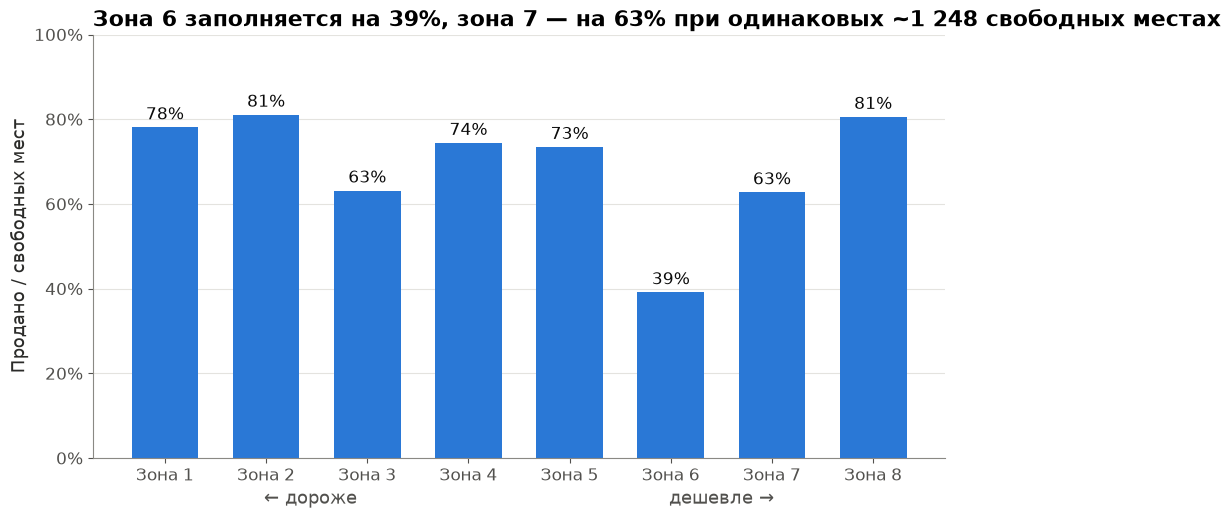

In [12]:
fz = hist.groupby("zone").agg(fill=("fill", "mean"), capacity=("capacity", "mean"), sold=("tickets_total", "mean"))
display(fz.round({"fill": 3, "capacity": 0, "sold": 0}))

fig, ax = plt.subplots(figsize=(11, 5.5))
bars = ax.bar(fz.index, fz["fill"], 0.66, color=MODEL_COLORS["catboost"])
ax.bar_label(bars, labels=[f"{v:.0%}" for v in fz["fill"]], padding=3, fontsize=12, color=INK)
ax.set_xticks(fz.index, [f"Зона {z}" for z in fz.index])
ax.set_xlabel("← дороже                                                    дешевле →", color=INK2)
ax.set_ylabel("Продано / свободных мест")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylim(0, 1)
ax.grid(axis="x", visible=False)
z6, z7 = fz.loc[6], fz.loc[7]
ax.set_title(f"Зона 6 заполняется на {z6['fill']:.0%}, зона 7 — на {z7['fill']:.0%} "
             f"при одинаковых ~{ru(z6['capacity'], 0)} свободных местах")
save(fig, "00_fill_by_zone.png")
plt.show()


### 2.1. RMSE трёх моделей: общий и по фолдам

сохранено: reports\figures\01_rmse_models.png


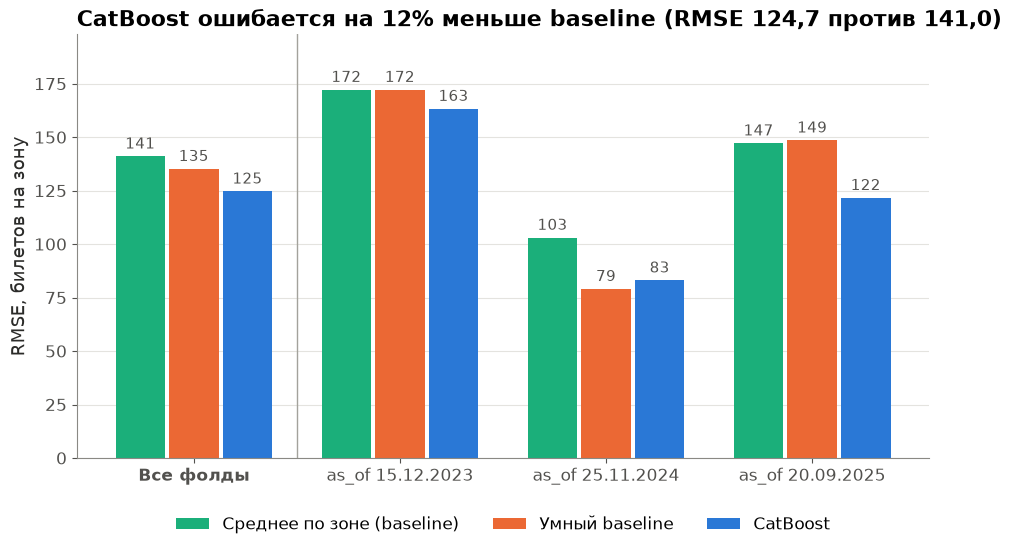

In [13]:
fold_names = {f: f"as_of {pd.Timestamp(f):%d.%m.%Y}" for f in FOLD_LABELS}
groups = ["все фолды"] + FOLD_LABELS
labels = ["Все фолды"] + [fold_names[f] for f in FOLD_LABELS]
order = ["zone_mean", "smart", "catboost"]

fig, ax = plt.subplots(figsize=(11, 5.5))
x, w = np.arange(len(groups)), 0.26
for i, name in enumerate(order):
    vals = by_fold.loc[groups, name].to_numpy()
    bars = ax.bar(x + (i - 1) * w, vals, w - 0.02, color=MODEL_COLORS[name], label=MODEL_NAMES[name])
    ax.bar_label(bars, labels=[f"{v:.0f}" for v in vals], padding=3, fontsize=11, color=INK2)
ax.set_xticks(x, labels)
ax.get_xticklabels()[0].set_fontweight("bold")
ax.axvline(0.5, color=MUTED, lw=1)
ax.set_ylabel("RMSE, билетов на зону")
ax.set_ylim(0, by_fold.to_numpy().max() * 1.15)
ax.grid(axis="x", visible=False)
gain = 1 - overall["catboost"] / overall["zone_mean"]
ax.set_title(f"CatBoost ошибается на {gain:.0%} меньше baseline (RMSE {ru(overall['catboost'])} против {ru(overall['zone_mean'])})")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
save(fig, "01_rmse_models.png")
plt.show()

### 2.2. RMSE по зонам

сохранено: reports\figures\02_rmse_by_zone.png


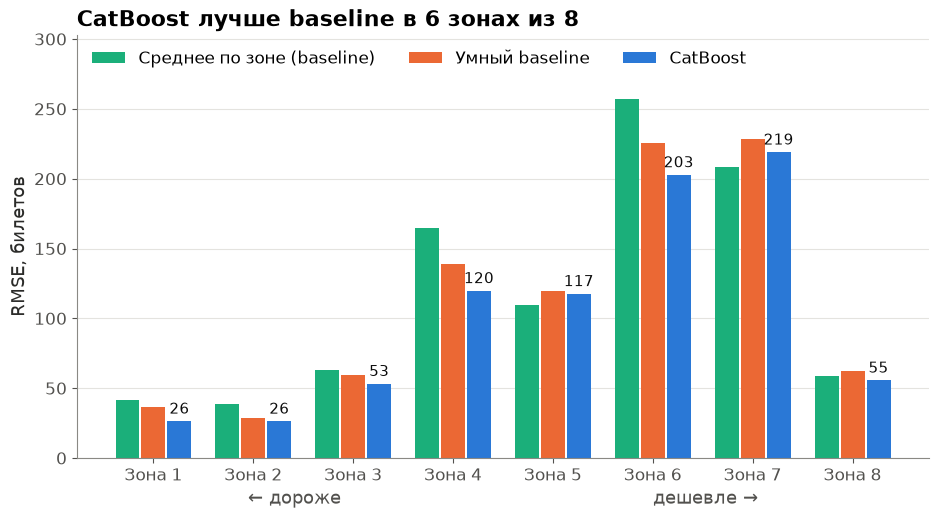

In [14]:
fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(1, 9)
for i, name in enumerate(order):
    bars = ax.bar(x + (i - 1) * w, by_zone[name], w - 0.02, color=MODEL_COLORS[name], label=MODEL_NAMES[name])
    if name == "catboost":
        ax.bar_label(bars, labels=[f"{v:.0f}" for v in by_zone[name]], padding=3, fontsize=11, color=INK)
ax.set_xticks(x, [f"Зона {z}" for z in x])
ax.set_xlabel("← дороже                                                    дешевле →", color=INK2)
ax.set_ylabel("RMSE, билетов")
ax.grid(axis="x", visible=False)
better = (by_zone["catboost"] < by_zone["zone_mean"]).sum()
ax.set_title(f"CatBoost лучше baseline в {better} зонах из 8")
ax.legend(loc="upper left", ncol=3)
ax.set_ylim(0, by_zone.to_numpy().max() * 1.18)
save(fig, "02_rmse_by_zone.png")
plt.show()

### 2.3. Факт vs прогноз CatBoost на валидации

сохранено: reports\figures\03_fact_vs_pred.png


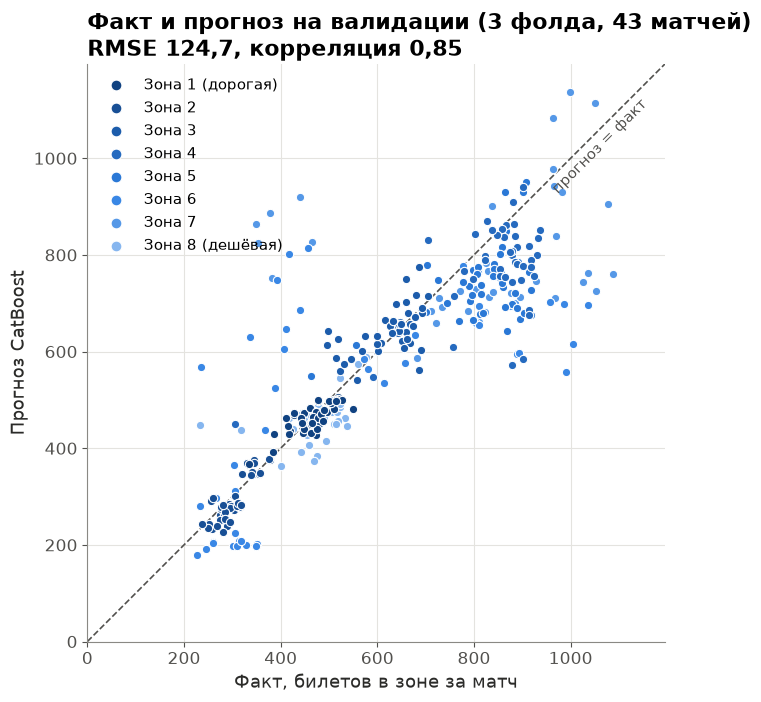

In [15]:
p = preds["catboost"]
fig, ax = plt.subplots(figsize=(8, 7.5))
for z in range(8, 0, -1):  # тёмные дорогие зоны рисуем последними, поверх
    s = p[p["zone"] == z]
    ax.scatter(s["y_true"], s["y_pred"], s=36, color=ZONE_COLORS[z], edgecolor="white", linewidth=0.8,
               label=f"Зона {z}", zorder=3)
lim = max(p["y_true"].max(), p["y_pred"].max()) * 1.05
ax.plot([0, lim], [0, lim], color=INK2, lw=1.2, ls="--", zorder=2)
ax.text(lim * 0.97, lim * 0.93, "прогноз = факт", ha="right", color=INK2, fontsize=11, rotation=45,
        rotation_mode="anchor")
ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_aspect("equal")
ax.set_xlabel("Факт, билетов в зоне за матч")
ax.set_ylabel("Прогноз CatBoost")
ax.set_title(f"Факт и прогноз на валидации (3 фолда, {p['match_id'].nunique()} матчей)\n"
             f"RMSE {ru(overall['catboost'])}, корреляция {ru(p['y_true'].corr(p['y_pred']), 2)}")
h, l = ax.get_legend_handles_labels()
ax.legend(h[::-1], [l + (" (дорогая)" if l == "Зона 1" else " (дешёвая)" if l == "Зона 8" else "")
                    for l in l[::-1]], loc="upper left", fontsize=11, markerscale=1.3)
save(fig, "03_fact_vs_pred.png")
plt.show()

### 2.4. Прогноз на 17 test-матчей

сохранено: reports\figures\04_test_forecast.png


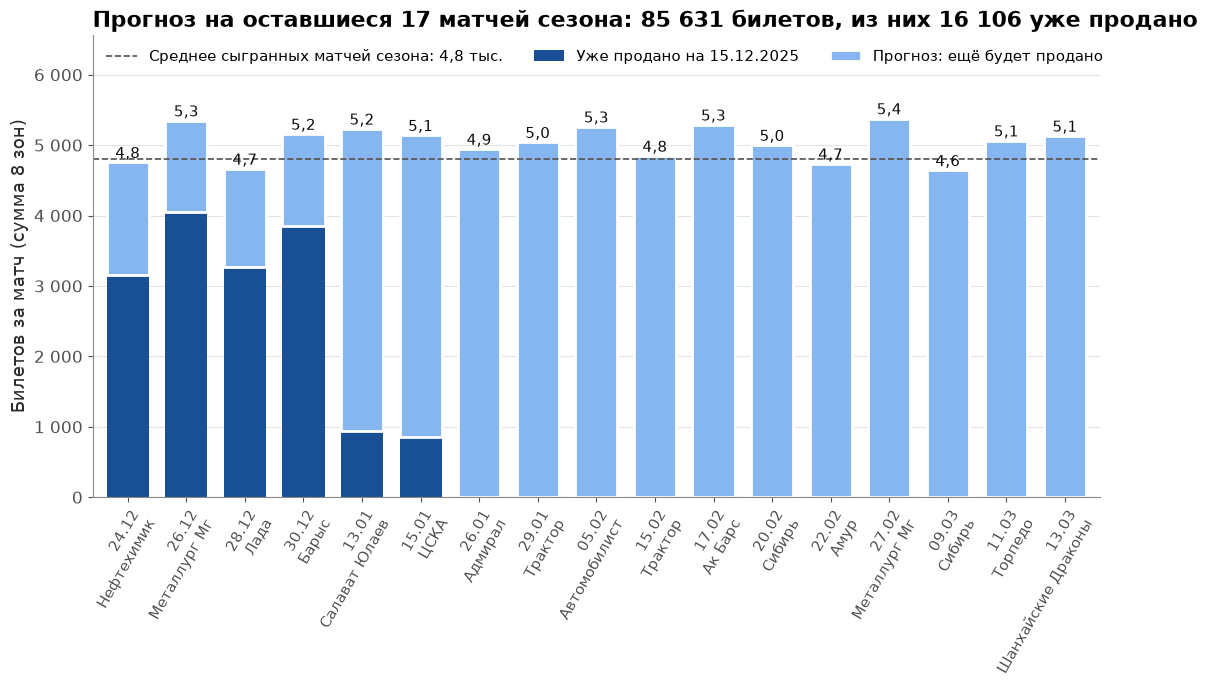

In [16]:
tm = test_m.sort_values("match_date").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(13, 6))
x = np.arange(len(tm))
ax.bar(x, tm["sold"], 0.72, color="#184f95", label="Уже продано на 15.12.2025")
ax.bar(x, tm["pred"] - tm["sold"], 0.72, bottom=tm["sold"], color="#86b6ef",
       edgecolor="white", linewidth=2, label="Прогноз: ещё будет продано")
for xi, v in zip(x, tm["pred"]):
    ax.text(xi, v + 60, ru(v / 1000), ha="center", fontsize=11, color=INK)
mean_cur = cur.mean()
ax.axhline(mean_cur, color=INK2, ls="--", lw=1.2, zorder=1,
           label=f"Среднее сыгранных матчей сезона: {ru(mean_cur / 1000)} тыс.")
ax.set_xticks(x, [f"{d:%d.%m}\n{o}" for d, o in zip(tm["match_date"], tm["opponent"])],
              rotation=60, ha="right", rotation_mode="anchor", fontsize=11)
ax.set_xlim(-0.6, len(tm) - 0.4)
ax.set_ylabel("Билетов за матч (сумма 8 зон)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: ru(v, 0)))
ax.grid(axis="x", visible=False)
ax.set_ylim(0, tm["pred"].max() * 1.22)
ax.set_title(f"Прогноз на оставшиеся 17 матчей сезона: {ru(tm['pred'].sum(), 0)} билетов, "
             f"из них {ru(tm['sold'].sum(), 0)} уже продано")
ax.legend(loc="upper left", ncol=3, fontsize=11)
save(fig, "04_test_forecast.png")
plt.show()

### 2.5. Схема валидации

сохранено: reports\figures\05_validation_scheme.png


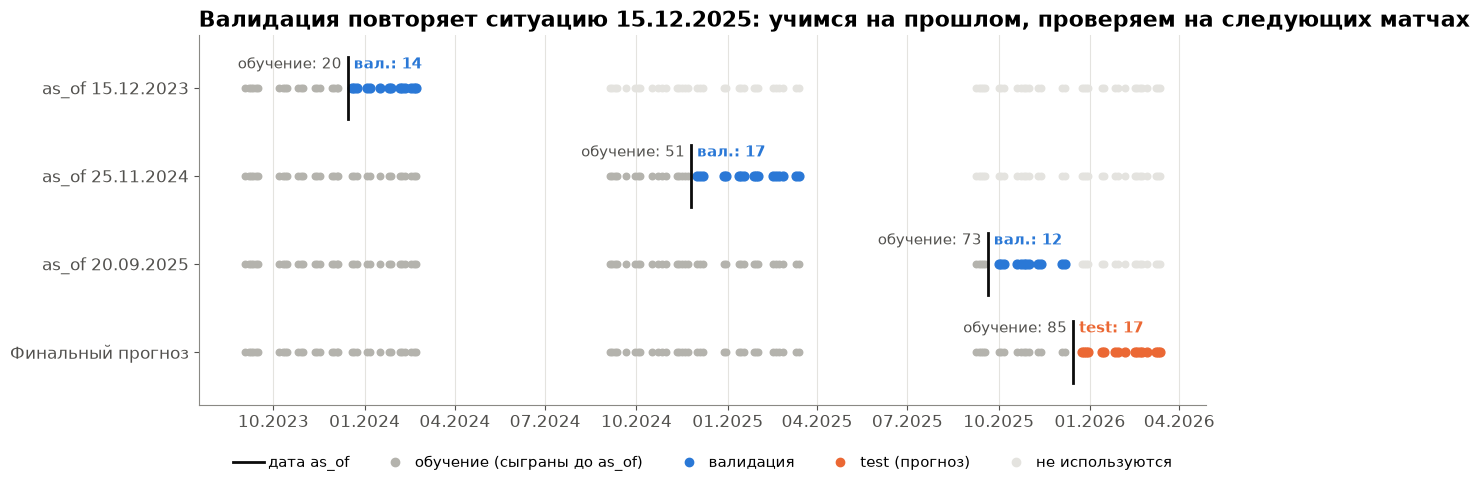

In [17]:
mt = df.drop_duplicates("match_id")[["match_id", "match_date", "is_test"]].sort_values("match_date")
VAL_C, TEST_C, TRAIN_C, REST_C = "#2a78d6", "#eb6834", "#b4b3ad", "#e4e3df"
rows_ = [(f, fold_names[f]) for f in FOLD_LABELS] + [("final", "Финальный прогноз")]

fig, ax = plt.subplots(figsize=(13, 4.8))
for i, (f, name) in enumerate(rows_):
    y = len(rows_) - 1 - i
    if f == "final":
        as_of, val_ids = pd.Timestamp("2025-12-15"), set(mt.loc[mt["is_test"] == 1, "match_id"])
        vc, n_lab = TEST_C, f"test: {len(val_ids)}"
    else:
        as_of = pd.Timestamp(f)
        val_ids = set(preds["catboost"].loc[preds["catboost"]["fold"] == f, "match_id"])
        vc, n_lab = VAL_C, f"вал.: {len(val_ids)}"
    tr = mt[(mt["match_date"] < as_of) & (mt["is_test"] == 0)]
    va = mt[mt["match_id"].isin(val_ids)]
    rest = mt[~mt["match_id"].isin(set(tr["match_id"]) | val_ids)]
    ax.scatter(rest["match_date"], [y] * len(rest), s=22, color=REST_C, zorder=2)
    ax.scatter(tr["match_date"], [y] * len(tr), s=22, color=TRAIN_C, zorder=2)
    ax.scatter(va["match_date"], [y] * len(va), s=40, color=vc, zorder=3)
    ax.plot([as_of, as_of], [y - 0.35, y + 0.35], color=INK, lw=2, zorder=4)
    ax.text(as_of - pd.Timedelta(days=6), y + 0.22, f"обучение: {len(tr)}", ha="right", fontsize=10.5, color=INK2)
    ax.text(as_of + pd.Timedelta(days=6), y + 0.22, n_lab, ha="left", fontsize=10.5, color=vc, fontweight="bold")
ax.set_yticks(range(len(rows_)), [n for _, n in rows_][::-1])
ax.set_ylim(-0.6, len(rows_) - 0.4)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{mdates.num2date(v):%m.%Y}"))
ax.set_title("Валидация повторяет ситуацию 15.12.2025: учимся на прошлом, проверяем на следующих матчах")
ax.legend(handles=[Line2D([], [], color=INK, lw=2, label="дата as_of"),
                   Line2D([], [], marker="o", ls="", color=TRAIN_C, label="обучение (сыграны до as_of)"),
                   Line2D([], [], marker="o", ls="", color=VAL_C, label="валидация"),
                   Line2D([], [], marker="o", ls="", color=TEST_C, label="test (прогноз)"),
                   Line2D([], [], marker="o", ls="", color=REST_C, label="не используются")],
          loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=5, fontsize=11, handletextpad=0.3)
save(fig, "05_validation_scheme.png")
plt.show()

### 2.6. Разбор ошибок: дни недели и соперники

Те же прогнозы валидации, что в 2.1–2.3 (3 фолда, 43 матча × 8 зон). `bias` = среднее (прогноз − факт):
< 0 — модель занижает. Строки — матч × зона, поэтому RMSE сопоставим с общим 124,7.

По соперникам выборка мала: с каждым соперником в валидации 1–5 матчей, поэтому RMSE по соперникам —
описание отдельных матчей, а не устойчивая оценка. Помечаем соперников, у которых меньше 3 матчей.

In [18]:
match_info = df.drop_duplicates("match_id").set_index("match_id")[["weekday", "opponent"]]
ev = preds["catboost"].join(match_info, on="match_id")
ev["y_base"] = preds["zone_mean"]["y_pred"].to_numpy()
assert (preds["zone_mean"][KEY].to_numpy() == ev[KEY].to_numpy()).all()


def err_stats(g):
    return pd.Series({"матчей": g["match_id"].nunique(), "строк": len(g),
                      "rmse_catboost": rmse(g["y_true"], g["y_pred"]),
                      "rmse_baseline": rmse(g["y_true"], g["y_base"]),
                      "bias_catboost": (g["y_pred"] - g["y_true"]).mean()})


by_wd = ev.groupby("weekday")[ev.columns].apply(err_stats)
by_wd.index = by_wd.index.map(WD)
by_wd[["матчей", "строк"]] = by_wd[["матчей", "строк"]].astype(int)
print("По дням недели:")
display(by_wd.round(1))

by_opp = ev.groupby("opponent")[ev.columns].apply(err_stats).sort_values("rmse_catboost", ascending=False)
by_opp[["матчей", "строк"]] = by_opp[["матчей", "строк"]].astype(int)
by_opp["мало_матчей"] = np.where(by_opp["матчей"] < 3, "да (< 3)", "")
print(f"По соперникам ({len(by_opp)}; матчей на соперника: {by_opp['матчей'].min()}–{by_opp['матчей'].max()}, "
      f"у {(by_opp['матчей'] < 3).sum()} из {len(by_opp)} меньше 3) — выборка мала:")
display(by_opp.round(1))


По дням недели:


,матчей,строк,rmse_catboost,rmse_baseline,bias_catboost
weekday,,,,,
пн,5,40,107.3,138.6,-57.0
вт,5,40,122.1,145.3,-25.1
ср,8,64,108.6,110.3,-31.9
чт,6,48,166.3,179.1,-16.1
пт,5,40,94.9,124.5,-51.7
сб,6,48,132.5,144.1,-13.3
вс,8,64,125.2,142.2,-8.4


По соперникам (20; матчей на соперника: 1–5, у 13 из 20 меньше 3) — выборка мала:


,матчей,строк,rmse_catboost,rmse_baseline,bias_catboost,мало_матчей
opponent,,,,,,
Сибирь,1,8,237.3,239.9,6.5,да (< 3)
Спартак,2,16,194.9,211.9,-41.6,да (< 3)
Лада,3,24,168.9,165.8,-24.3,
СКА,2,16,150.3,183.4,-28.4,да (< 3)
Металлург Мг,5,40,145.6,155.4,-19.0,
Сочи,3,24,135.0,168.5,30.2,
Нефтехимик,1,8,134.2,171.5,-45.1,да (< 3)
Витязь,1,8,132.7,120.7,-92.8,да (< 3)
Торпедо,1,8,124.0,95.9,-97.6,да (< 3)


сохранено: reports\figures\06_errors_weekday.png


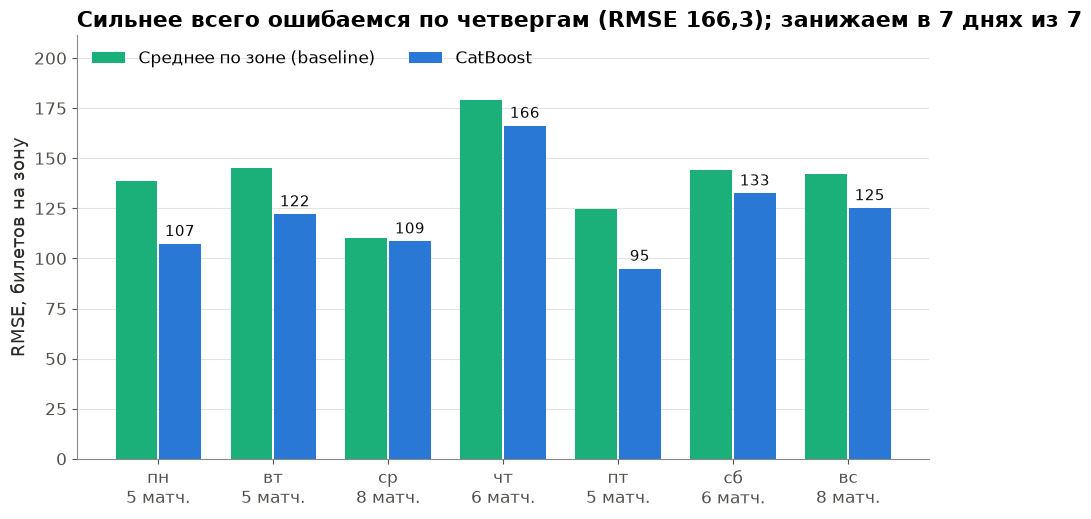

In [19]:
fig, ax = plt.subplots(figsize=(11, 5.5))
x, w = np.arange(len(by_wd)), 0.38
for i, (name, col) in enumerate([("zone_mean", "rmse_baseline"), ("catboost", "rmse_catboost")]):
    bars = ax.bar(x + (i - 0.5) * w, by_wd[col], w - 0.02, color=MODEL_COLORS[name], label=MODEL_NAMES[name])
    if name == "catboost":
        ax.bar_label(bars, labels=[f"{v:.0f}" for v in by_wd[col]], padding=3, fontsize=11, color=INK)
ax.set_xticks(x, [f"{d}\n{n} матч." for d, n in zip(by_wd.index, by_wd["матчей"])])
ax.set_ylabel("RMSE, билетов на зону")
ax.set_ylim(0, by_wd[["rmse_catboost", "rmse_baseline"]].to_numpy().max() * 1.18)
ax.grid(axis="x", visible=False)
WD_PLURAL = {"пн": "понедельникам", "вт": "вторникам", "ср": "средам", "чт": "четвергам",
             "пт": "пятницам", "сб": "субботам", "вс": "воскресеньям"}
worst = by_wd["rmse_catboost"].idxmax()
under = (by_wd["bias_catboost"] < 0).sum()
ax.set_title(f"Сильнее всего ошибаемся по {WD_PLURAL[worst]} (RMSE {ru(by_wd.loc[worst, 'rmse_catboost'])}); "
             f"занижаем в {under} днях из {len(by_wd)}")
ax.legend(loc="upper left", ncol=2)
save(fig, "06_errors_weekday.png")
plt.show()


In [20]:
# Откуда ошибка худшего дня: по матчам и по зонам. Плюс общее смещение CatBoost на валидации.
ev["se"] = (ev["y_pred"] - ev["y_true"]) ** 2
wd_rows = ev[ev["weekday"].map(WD) == worst]
per_match = (wd_rows.groupby(["fold", "match_id", "opponent"])["se"].mean() ** 0.5).round(0).rename("rmse")
zone_share = (wd_rows.groupby("zone")["se"].sum() / wd_rows["se"].sum()).round(2).rename("доля_ошибки")
print(f"День «{worst}»: RMSE по матчам")
display(per_match.to_frame())
print(f"Доля квадратичной ошибки дня «{worst}» по зонам (зоны 6+7: {zone_share.loc[[6, 7]].sum():.0%}):")
display(zone_share.to_frame().T)
print(f"Среднее смещение CatBoost (прогноз − факт) по всем строкам валидации: {(ev['y_pred'] - ev['y_true']).mean():.1f}")


День «чт»: RMSE по матчам


rmse
fold       match_id opponent         
2023-12-15 M022     Сочи         66.0
           M030     Спартак     245.0
           M034     Лада        228.0
2025-09-20 M078     Северсталь   61.0
           M083     Трактор      62.0
           M084     Сочи        205.0

Доля квадратичной ошибки дня «чт» по зонам (зоны 6+7: 64%):


zone,1,2,3,4,5,6,7,8
доля_ошибки,0.0,0.0,0.01,0.2,0.1,0.22,0.42,0.05


Среднее смещение CatBoost (прогноз − факт) по всем строкам валидации: -27.2


## Часть 3. Значимость выигрыша

Бутстрэп по матчам: 2000 раз выбираем с возвращением 43 матча проверки (все 8 зон каждого матча
идут вместе; матч, выпавший дважды, учитывается дважды) и считаем RMSE трёх моделей на одной и той же
выборке. Разница `catboost − baseline` < 0 — CatBoost лучше. Модели не переобучаются: берутся
прогнозы валидации из кэша (`preds`). 95% ДИ — перцентили 2,5 и 97,5. `random_state = 42`.

Единица — матч, а не строка: зоны одного матча сильно связаны (общий спрос на матч), бутстрэп по строкам
дал бы слишком узкий интервал.

In [21]:
N_BOOT = 2000
cols = ["fold", "match_id", "zone", "y_true"]
for name in ("smart", "zone_mean"):
    assert preds[name][cols].equals(preds["catboost"][cols]), f"строки {name} и catboost не совпадают"

match_codes, matches = pd.factorize(preds["catboost"]["match_id"])
y_true = preds["catboost"]["y_true"].to_numpy(float)
# Сумма квадратов ошибок и число строк по матчу: RMSE повтора = sqrt(Σ SSE / Σ строк) с кратностями матчей
sse = {n: np.bincount(match_codes, weights=(p["y_pred"].to_numpy(float) - y_true) ** 2) for n, p in preds.items()}
n_rows = np.bincount(match_codes)

rng = np.random.default_rng(RANDOM_STATE)
draws = rng.integers(0, len(matches), size=(N_BOOT, len(matches)))
mult = np.stack([np.bincount(d, minlength=len(matches)) for d in draws])  # кратность матча в повторе
boot_rmse = {n: np.sqrt(mult @ s / (mult @ n_rows)) for n, s in sse.items()}

rows = []
for base in ("smart", "zone_mean"):
    d = boot_rmse["catboost"] - boot_rmse[base]
    rows.append({"сравнение": f"CatBoost − {MODEL_NAMES[base]}",
                 "разница_на_проверке": overall["catboost"] - overall[base],
                 "средняя_разница": d.mean(),
                 "ДИ95_низ": np.percentile(d, 2.5), "ДИ95_верх": np.percentile(d, 97.5),
                 "повторов_catboost_лучше": int((d < 0).sum()), "доля_catboost_лучше": (d < 0).mean()})
boot = pd.DataFrame(rows).set_index("сравнение")
print(f"Бутстрэп: {N_BOOT} повторов по {len(matches)} матчам")
display(boot.round({"разница_на_проверке": 1, "средняя_разница": 1, "ДИ95_низ": 1, "ДИ95_верх": 1,
                    "доля_catboost_лучше": 2}))
# Для assert: средняя разница и ДИ до 0,1 и число повторов, где CatBoost лучше (целое — без двусмысленного округления доли)
BOOT_KEYS = {}
for b in ("smart", "zone_mean"):
    r = boot.loc[f"CatBoost − {MODEL_NAMES[b]}"]
    BOOT_KEYS[f"boot_{b}"] = (round(float(r["средняя_разница"]), 1), round(float(r["ДИ95_низ"]), 1),
                              round(float(r["ДИ95_верх"]), 1), int(r["повторов_catboost_лучше"]))
print("Для assert:", BOOT_KEYS)


Бутстрэп: 2000 повторов по 43 матчам


,разница_на_проверке,средняя_разница,ДИ95_низ,ДИ95_верх,повторов_catboost_лучше,доля_catboost_лучше
сравнение,,,,,,
CatBoost − Умный baseline,-10.5,-10.5,-20.4,-0.1,1953,0.98
CatBoost − Среднее по зоне (baseline),-16.4,-16.4,-25.5,-7.2,1999,1.00


Для assert: {'boot_smart': (-10.5, -20.4, -0.1, 1953), 'boot_zone_mean': (-16.4, -25.5, -7.2, 1999)}


## Часть 4. Неопределённость и бизнес-метрики

Модель не меняется: интервалы строятся по остаткам CatBoost на валидации из кэша (`preds["catboost"]`,
3 фолда, 43 матча × 8 зон). Остаток = факт − прогноз. Интервал 10–90%: `[прогноз + q10; прогноз + q90]`,
то есть номинально 80% фактов должны в него попадать.

Два уровня:
- **зона** — квантили остатка в билетах по группе зон × статусу продаж (4.1–4.2);
- **матч** — сумма зональных границ по 8 зонам (4.3). Прямой интервал по относительному остатку суммы матча
  проверен как альтернатива и не используется: покрытие 60% при номинале 80% (4.3).

Покрытие проверяем честно, leave-one-fold-out: квантили по двум фолдам, покрытие на третьем.
На валидации границы обрезаются так же, как на тесте: `sold_as_of ≤ low`, `high ≤ capacity`
(из `build_table(as_of)` своего фолда).

Оговорка: строки одного матча и матчи одного фолда связаны (общий спрос), фолдов всего 3, поэтому
покрытие — ориентир, а не точная оценка.

### 4.1. Группы зон по вместимости

Разбивка зона × статус слишком мелкая: матчей «в продаже» на валидации 13, при leave-one-fold-out на
обучающих фолдах остаётся 8–10 строк на зону — квантиль 10% по ним по сути минимум. Поэтому зоны
объединяем. Правило не использует ошибки валидации (иначе это подгонка под ту же выборку): зоны
сортируются по средней capacity (`seats − season_tickets`, известна заранее) и делятся на 3 группы подряд
идущих зон с минимальной внутригрупповой суммой квадратов capacity (natural breaks / Jenks, полный перебор
21 варианта). Простое «резать по двум самым большим разрывам» здесь неоднозначно: разрывы 2→8 (180 мест)
и 4→6 (177) почти равны. Масштаб остатков в билетах растёт вместе с размером зоны, поэтому внутри группы
остатки в билетах сопоставимы.

Откат: если в клетке «группа × статус» на обучающих фолдах меньше `MIN_ROWS = 20` строк, берём квантили
группы зон без разбивки по статусу.

In [22]:
import itertools

Q_LO, Q_HI = 0.1, 0.9
MIN_ROWS, MIN_MATCHES = 20, 10  # пороги отката: строк на клетку зон, матчей на статус

N_GROUPS = 3

zone_cap = df.groupby("zone")["capacity"].mean().sort_values()
gap = zone_cap.diff()
# Natural breaks: все разбиения отсортированного ряда на N_GROUPS подряд идущих групп,
# минимум внутригрупповой суммы квадратов
splits = []
for cuts in itertools.combinations(range(1, len(zone_cap)), N_GROUPS - 1):
    parts = np.split(zone_cap.to_numpy(), cuts)
    zs = np.split(zone_cap.index.to_numpy(), cuts)
    splits.append({"группы": " / ".join("{" + ",".join(map(str, sorted(z))) + "}" for z in zs),
                   "SSE_capacity": sum(((p - p.mean()) ** 2).sum() for p in parts), "cuts": cuts})
splits = pd.DataFrame(splits).sort_values("SSE_capacity").reset_index(drop=True)
print("Лучшие разбиения на 3 группы по вместимости:")
display(splits[["группы", "SSE_capacity"]].head(5).round(0))
starts = zone_cap.index[list(splits.loc[0, "cuts"])]  # зоны, с которых начинается следующая группа
ZONE_GROUP = dict(zip(zone_cap.index, zone_cap.index.isin(starts).cumsum()))
GROUP_LABEL = {g: "зоны " + ", ".join(str(z) for z in sorted(z for z, gg in ZONE_GROUP.items() if gg == g))
               for g in sorted(set(ZONE_GROUP.values()))}
display(pd.DataFrame({"capacity_ср": zone_cap.round(0), "разрыв_с_предыдущей": gap.round(0),
                      "группа": zone_cap.index.map(ZONE_GROUP).map(GROUP_LABEL)}))
ZONE_GROUPS = tuple(tuple(sorted(z for z, g in ZONE_GROUP.items() if g == k)) for k in sorted(GROUP_LABEL))
print("Группы зон:", ZONE_GROUPS)
assert ZONE_GROUPS == ((1, 2, 8), (3, 4, 5), (6, 7)), ZONE_GROUPS  # согласованы с командой

Лучшие разбиения на 3 группы по вместимости:


,группы,SSE_capacity
0,"{1,2,8} / {3,4,5} / {6,7}",29159.0
1,"{1,2,8} / {3,5} / {4,6,7}",49644.0
2,"{2} / {1,8} / {3,4,5,6,7}",52840.0
3,"{1,2,8} / {3,4,5,6} / {7}",59840.0
4,"{1,2,8} / {3} / {4,5,6,7}",62332.0


,capacity_ср,разрыв_с_предыдущей,группа
zone,,,
2,373.0,NaN,"зоны 1, 2, 8"
8,554.0,180.0,"зоны 1, 2, 8"
1,592.0,38.0,"зоны 1, 2, 8"
3,998.0,407.0,"зоны 3, 4, 5"
5,1043.0,44.0,"зоны 3, 4, 5"
4,1058.0,16.0,"зоны 3, 4, 5"
6,1236.0,177.0,"зоны 6, 7"
7,1240.0,4.0,"зоны 6, 7"


Группы зон: ((1, 2, 8), (3, 4, 5), (6, 7))


In [23]:
# Валидационные строки CatBoost + sold_as_of и capacity на дату своего фолда
fold_tab = {f: build_table(f).set_index(KEY)[["sold_as_of", "capacity"]] for f in FOLD_LABELS}
ev_i = pd.concat([g.join(fold_tab[f], on=KEY) for f, g in preds["catboost"].groupby("fold", sort=False)])
assert len(ev_i) == len(preds["catboost"])
assert ev_i["y_true"].between(ev_i["sold_as_of"], ev_i["capacity"]).all()
assert ev_i["y_pred"].between(ev_i["sold_as_of"], ev_i["capacity"]).all()
ev_i["zgroup"] = ev_i["zone"].map(ZONE_GROUP)
ev_i["resid"] = ev_i["y_true"] - ev_i["y_pred"]
STATUS = {True: "в продаже", False: "не в продаже"}


def clip_interval(pred, lo, hi, floor_, cap):
    # Целые границы: floor_ <= low <= pred <= high <= cap
    low = np.maximum(np.floor(lo), floor_)
    high = np.minimum(np.ceil(hi), cap)
    return np.minimum(low, pred).astype(int), np.maximum(high, pred).astype(int)


def zone_quantiles(train):
    # Квантили остатка (билеты) по группе зон × статусу; < MIN_ROWS строк → по группе зон целиком
    rows = []
    for g in sorted(GROUP_LABEL):
        for s in (True, False):
            r, level = train.loc[(train["zgroup"] == g) & (train["in_sale"] == s), "resid"], "группа × статус"
            n_cell = len(r)
            if n_cell < MIN_ROWS:
                r, level = train.loc[train["zgroup"] == g, "resid"], "группа (откат)"
            rows.append({"zgroup": g, "in_sale": s, "строк_в_клетке": n_cell, "уровень": level,
                         "строк_для_квантиля": len(r), "q_lo": r.quantile(Q_LO), "q_hi": r.quantile(Q_HI)})
    return pd.DataFrame(rows).set_index(["zgroup", "in_sale"])


def zone_interval(rows, q, pred_col):
    qq = q.reindex(pd.MultiIndex.from_arrays([rows["zgroup"], rows["in_sale"]]))
    pred = rows[pred_col].to_numpy()
    return clip_interval(pred, pred + qq["q_lo"].to_numpy(), pred + qq["q_hi"].to_numpy(),
                         rows["sold_as_of"].to_numpy(), rows["capacity"].to_numpy())


# Leave-one-fold-out: квантили по двум фолдам → интервал на третьем
parts, q_folds = [], []
for f in FOLD_LABELS:
    q = zone_quantiles(ev_i[ev_i["fold"] != f])
    part = ev_i[ev_i["fold"] == f].copy()
    part["low"], part["high"] = zone_interval(part, q, "y_pred")
    parts.append(part)
    q_folds.append(q.assign(фолд_проверки=f))
lofo_z = pd.concat(parts)
lofo_z["covered"] = lofo_z["y_true"].between(lofo_z["low"], lofo_z["high"])
q_folds = pd.concat(q_folds).reset_index()
q_folds["группа"] = q_folds["zgroup"].map(GROUP_LABEL)
q_folds["статус"] = q_folds["in_sale"].map(STATUS)
print("Квантили LOFO по фолдам (обучение — два других фолда):")
display(q_folds[["фолд_проверки", "группа", "статус", "строк_в_клетке", "уровень", "строк_для_квантиля",
                 "q_lo", "q_hi"]].round(1))
n_fallback = int((q_folds["уровень"] != "группа × статус").sum())
print(f"Откатов на группу зон: {n_fallback} из {len(q_folds)}")

Квантили LOFO по фолдам (обучение — два других фолда):


,фолд_проверки,группа,статус,строк_в_клетке,уровень,строк_для_квантиля,q_lo,q_hi
0,2023-12-15,"зоны 1, 2, 8",в продаже,24,группа × статус,24,-19.0,36.1
1,2023-12-15,"зоны 1, 2, 8",не в продаже,63,группа × статус,63,-15.6,46.4
2,2023-12-15,"зоны 3, 4, 5",в продаже,24,группа × статус,24,-47.6,148.4
3,2023-12-15,"зоны 3, 4, 5",не в продаже,63,группа × статус,63,-43.4,143.8
4,2023-12-15,"зоны 6, 7",в продаже,16,группа (откат),58,-35.8,261.8
5,2023-12-15,"зоны 6, 7",не в продаже,42,группа × статус,42,18.1,271.4
6,2024-11-25,"зоны 1, 2, 8",в продаже,24,группа × статус,24,-35.1,36.1
7,2024-11-25,"зоны 1, 2, 8",не в продаже,54,группа × статус,54,-28.7,50.0
8,2024-11-25,"зоны 3, 4, 5",в продаже,24,группа × статус,24,-83.6,129.4
9,2024-11-25,"зоны 3, 4, 5",не в продаже,54,группа × статус,54,-31.4,176.7


Откатов на группу зон: 2 из 18


### 4.2. Покрытие зональных интервалов (leave-one-fold-out)

**Зональные интервалы — ориентир; на валидации покрытие 69% при номинале 80%.**

`покрытие` — доля фактов внутри `[low; high]`; `ниже` / `выше` — факт ниже low / выше high
(номинально по 10%). `ширина` — средняя `high − low`, билетов.

In [24]:
def coverage(g, lo="low", hi="high"):
    return pd.Series({"строк": len(g), "покрытие": g["y_true"].between(g[lo], g[hi]).mean(),
                      "ниже": (g["y_true"] < g[lo]).mean(), "выше": (g["y_true"] > g[hi]).mean(),
                      "ширина": (g[hi] - g[lo]).mean()})


cov_z = pd.concat({
    "все строки": coverage(lofo_z).to_frame().T,
    "по фолдам": lofo_z.groupby("fold")[lofo_z.columns].apply(coverage),
    "по статусу": lofo_z.groupby(lofo_z["in_sale"].map(STATUS))[lofo_z.columns].apply(coverage),
    "по группам зон": lofo_z.groupby(lofo_z["zgroup"].map(GROUP_LABEL))[lofo_z.columns].apply(coverage),
})
cov_z["строк"] = cov_z["строк"].astype(int)
display(cov_z.round({"покрытие": 2, "ниже": 2, "выше": 2, "ширина": 0}))
COV_ZONE = (int(lofo_z["covered"].sum()), len(lofo_z))
print(f"Покрытие зональных интервалов LOFO: {COV_ZONE[0]} из {COV_ZONE[1]} строк ({COV_ZONE[0] / COV_ZONE[1]:.0%}) "
      f"при номинале {Q_HI - Q_LO:.0%}")

строк  покрытие  ниже  выше  ширина
все строки     0               344      0.69  0.18  0.13   224.0
по фолдам      2023-12-15      112      0.51  0.35  0.14   161.0
               2024-11-25      136      0.86  0.07  0.07   262.0
               2025-09-20       96      0.67  0.14  0.20   244.0
по статусу     в продаже       104      0.57  0.27  0.16   204.0
               не в продаже    240      0.75  0.14  0.12   233.0
по группам зон зоны 1, 2, 8    129      0.72  0.17  0.11    71.0
               зоны 3, 4, 5    129      0.71  0.16  0.13   203.0
               зоны 6, 7        86      0.63  0.21  0.16   487.0

Покрытие зональных интервалов LOFO: 238 из 344 строк (69%) при номинале 80%


### 4.3. Интервал на матч: сумма зональных границ против прямого

**Прямой.** Остаток суммы по матчу в относительных единицах: `rel = (факт − прогноз) / прогноз` (сумма 8 зон).
Квантили 10/90% `rel` по статусу продаж; если на обучающих фолдах матчей с этим статусом меньше
`MIN_MATCHES = 10`, берём квантили по всем матчам. Интервал `[прогноз·(1 + q10); прогноз·(1 + q90)]`,
затем `Σ sold_as_of ≤ low`, `high ≤ Σ capacity`.

**Сумма зональных границ.** `Σ low` и `Σ high` из 4.1. Квантили не складываются: сумма границ равна
10–90% интервалу матча, только если все зоны ошибаются в одну сторону одновременно, иначе она шире.
Для общего спроса на матч это допущение близко к правде: зоны одного матча связаны.

In [25]:
mlev = lofo_z.groupby(["fold", "match_id"], sort=False).agg(
    in_sale=("in_sale", "first"), y_true=("y_true", "sum"), y_pred=("y_pred", "sum"),
    sold_as_of=("sold_as_of", "sum"), capacity=("capacity", "sum"),
    low_sum=("low", "sum"), high_sum=("high", "sum")).reset_index()
mlev["rel"] = (mlev["y_true"] - mlev["y_pred"]) / mlev["y_pred"]


def match_quantiles(train):
    # Квантили относительного остатка матча по статусу; < MIN_MATCHES матчей → по всем матчам
    rows = []
    for s in (True, False):
        r, level = train.loc[train["in_sale"] == s, "rel"], "статус"
        n_cell = len(r)
        if n_cell < MIN_MATCHES:
            r, level = train["rel"], "все матчи (откат)"
        rows.append({"in_sale": s, "матчей_со_статусом": n_cell, "уровень": level,
                     "матчей_для_квантиля": len(r), "q_lo": r.quantile(Q_LO), "q_hi": r.quantile(Q_HI)})
    return pd.DataFrame(rows).set_index("in_sale")


def match_interval(rows, q, pred_col, sold_col, cap_col):
    qq = q.reindex(rows["in_sale"])
    pred = rows[pred_col].to_numpy()
    return clip_interval(pred, pred * (1 + qq["q_lo"].to_numpy()), pred * (1 + qq["q_hi"].to_numpy()),
                         rows[sold_col].to_numpy(), rows[cap_col].to_numpy())


parts, qm_folds = [], []
for f in FOLD_LABELS:
    q = match_quantiles(mlev[mlev["fold"] != f])
    part = mlev[mlev["fold"] == f].copy()
    part["low"], part["high"] = match_interval(part, q, "y_pred", "sold_as_of", "capacity")
    parts.append(part)
    qm_folds.append(q.assign(фолд_проверки=f))
lofo_m = pd.concat(parts)
qm_folds = pd.concat(qm_folds).reset_index()
qm_folds["статус"] = qm_folds["in_sale"].map(STATUS)
print("Квантили относительного остатка матча, LOFO:")
display(qm_folds[["фолд_проверки", "статус", "матчей_со_статусом", "уровень", "матчей_для_квантиля",
                  "q_lo", "q_hi"]].round(3))


def coverage_m(g):
    out = {}
    for name, lo, hi in (("прямой", "low", "high"), ("сумма зон", "low_sum", "high_sum")):
        c = coverage(g, lo, hi)
        out[(name, "покрытие")], out[(name, "ширина")] = c["покрытие"], c["ширина"]
        out[(name, "ширина_%_вмест")] = ((g[hi] - g[lo]) / g["capacity"]).mean() * 100
        out[(name, "ниже")], out[(name, "выше")] = c["ниже"], c["выше"]
    out[("", "матчей")] = len(g)
    return pd.Series(out)


cov_m = pd.concat({
    "все матчи": coverage_m(lofo_m).to_frame().T,
    "по фолдам": lofo_m.groupby("fold")[lofo_m.columns].apply(coverage_m),
    "по статусу": lofo_m.groupby(lofo_m["in_sale"].map(STATUS))[lofo_m.columns].apply(coverage_m),
})
cov_m[("", "матчей")] = cov_m[("", "матчей")].astype(int)
display(cov_m.round(2))
COV_MATCH_DIRECT = (int(lofo_m["y_true"].between(lofo_m["low"], lofo_m["high"]).sum()), len(lofo_m))
COV_MATCH_SUM = (int(lofo_m["y_true"].between(lofo_m["low_sum"], lofo_m["high_sum"]).sum()), len(lofo_m))
print(f"Покрытие на матч LOFO: прямой {COV_MATCH_DIRECT[0]} из {COV_MATCH_DIRECT[1]}, "
      f"сумма зональных границ {COV_MATCH_SUM[0]} из {COV_MATCH_SUM[1]}")

Квантили относительного остатка матча, LOFO:


,фолд_проверки,статус,матчей_со_статусом,уровень,матчей_для_квантиля,q_lo,q_hi
0,2023-12-15,в продаже,8,все матчи (откат),29,0.010,0.163
1,2023-12-15,не в продаже,21,статус,21,0.042,0.161
2,2024-11-25,в продаже,8,все матчи (откат),26,-0.114,0.122
3,2024-11-25,не в продаже,18,статус,18,-0.003,0.113
4,2025-09-20,в продаже,10,статус,10,-0.119,0.047
5,2025-09-20,не в продаже,21,статус,21,0.002,0.146


прямой                                    сумма зон                                           
                        покрытие  ширина ширина_%_вмест  ниже  выше  покрытие   ширина ширина_%_вмест  ниже  выше матчей
все матчи  0                0.60  718.65          10.11  0.16  0.23      0.88  1794.58          25.33  0.09  0.02     43
по фолдам  2023-12-15       0.57  812.64          11.14  0.43  0.00      0.71  1290.79          17.73  0.29  0.00     14
           2024-11-25       0.65  645.76           9.13  0.00  0.35      1.00  2099.00          29.54  0.00  0.00     17
           2025-09-20       0.58  712.25          10.29  0.08  0.33      0.92  1951.08          28.22  0.00  0.08     12
по статусу в продаже        0.31  897.23          12.77  0.38  0.31      0.62  1630.38          23.28  0.31  0.08     13
           не в продаже     0.73  641.27           8.95  0.07  0.20      1.00  1865.73          26.21  0.00  0.00     30

Покрытие на матч LOFO: прямой 26 из 43, сумма зональных границ 38 из 43


**Решение: интервал на матч = сумма зональных границ** (покрытие LOFO 38 из 43 матчей, 88%).

Прямой интервал не используем: покрытие 26 из 43 (60%), у матчей в продаже 4 из 13. Он не учитывает
межсезонный сдвиг уровня спроса: относительный остаток матча почти одинаков внутри сезона и смещается
между сезонами (на фолде 15.12.2023 факт ниже интервала у 43% матчей, на двух других выше у трети),
поэтому квантили по двум сезонам плохо переносятся на третий. Сумма зональных границ шире
(25% вместимости против 10%), но держит номинал.

### 4.4. Интервалы для 136 строк теста и 17 матчей

Квантили — по всем трём фолдам валидации (на тесте модель обучена на всех 85 матчах, это ближе
к самому полному фолду). Статус — `sales_started` на 15.12.2025. Границы: `sold_as_of ≤ low ≤ pred ≤ high ≤ capacity`.

- `submissions/prediction_intervals.csv` — по строкам: `match_id, zone, pred, low, high`.
  **Ориентир; на валидации покрытие 69% при номинале 80%.**
- `submissions/prediction_intervals_by_match.csv` — по матчам: сумма зональных границ (4.3),
  на валидации покрытие 88%. Прямой интервал — только в таблице ниже, для сравнения.

In [26]:
SUB_DIR = ROOT / "submissions"
q_zone_full = zone_quantiles(ev_i)
q_match_full = match_quantiles(mlev)
print("Квантили для теста, зоны (билеты):")
display(q_zone_full.rename(index=GROUP_LABEL, level=0).rename(index=STATUS, level=1).round(1))
print("Квантили для теста, матч (доля прогноза):")
display(q_match_full.rename(index=STATUS).round(3))

ti = test.assign(in_sale=test["sales_started"].astype(bool), zgroup=test["zone"].map(ZONE_GROUP))
ti["low"], ti["high"] = zone_interval(ti, q_zone_full, "pred")
assert len(ti) == 136
assert ((ti["sold_as_of"] <= ti["low"]) & (ti["low"] <= ti["pred"]) & (ti["pred"] <= ti["high"])
        & (ti["high"] <= ti["capacity"])).all()
ti[KEY + ["pred", "low", "high"]].to_csv(SUB_DIR / "prediction_intervals.csv", index=False, encoding="utf-8")

tmi = test_m.assign(in_sale=test_m["sales_started"].astype(bool)).sort_values("match_date").reset_index(drop=True)
# Интервал на матч — сумма зональных границ; прямой — для сравнения
tmi["low_direct"], tmi["high_direct"] = match_interval(tmi, q_match_full, "pred", "sold", "capacity")
tmi = tmi.join(ti.groupby("match_id")[["low", "high"]].sum(), on="match_id")
assert ((tmi["sold"] <= tmi["low"]) & (tmi["low"] <= tmi["pred"]) & (tmi["pred"] <= tmi["high"])
        & (tmi["high"] <= tmi["capacity"])).all()
by_match_cols = ["match_id", "match_date", "opponent", "sales_started", "sold", "pred", "low", "high", "capacity"]
(tmi[by_match_cols].assign(match_date=tmi["match_date"].dt.strftime("%Y-%m-%d"))
 .to_csv(SUB_DIR / "prediction_intervals_by_match.csv", index=False, encoding="utf-8"))
print("сохранено: submissions/prediction_intervals.csv, submissions/prediction_intervals_by_match.csv")

show = tmi[by_match_cols + ["low_direct", "high_direct"]].copy()
show["ширина_%_вмест"] = (show["high"] - show["low"]) / show["capacity"] * 100
display(show.assign(match_date=show["match_date"].dt.strftime("%d.%m.%Y")).round(1))
TEST_INTERVAL = (int(tmi["low"].sum()), int(tmi["pred"].sum()), int(tmi["high"].sum()))
print(f"Сумма по 17 матчам: прогноз {TEST_INTERVAL[1]}, сумма границ интервалов матчей "
      f"{TEST_INTERVAL[0]}–{TEST_INTERVAL[2]}")

Квантили для теста, зоны (билеты):


строк_в_клетке          уровень  строк_для_квантиля   q_lo   q_hi
zgroup       in_sale                                                                        
зоны 1, 2, 8 в продаже                 39  группа × статус                  39  -36.4   34.6
             не в продаже              90  группа × статус                  90  -25.1   50.2
зоны 3, 4, 5 в продаже                 39  группа × статус                  39  -74.4  138.2
             не в продаже              90  группа × статус                  90  -33.3  173.7
зоны 6, 7    в продаже                 26  группа × статус                  26 -324.5  176.5
             не в продаже              60  группа × статус                  60 -335.0  288.9

Квантили для теста, матч (доля прогноза):


,матчей_со_статусом,уровень,матчей_для_квантиля,q_lo,q_hi
in_sale,,,,,
в продаже,13,статус,13,-0.117,0.134
не в продаже,30,статус,30,0.002,0.147


сохранено: submissions/prediction_intervals.csv, submissions/prediction_intervals_by_match.csv


,match_id,match_date,opponent,sales_started,sold,pred,low,high,capacity,low_direct,high_direct,ширина_%_вмест
0,M086,24.12.2025,Нефтехимик,1,3152,4757,3857,5633,6916,4200,5395,25.7
1,M087,26.12.2025,Металлург Мг,1,4056,5348,4618,6224,6916,4722,6065,23.2
2,M088,28.12.2025,Лада,1,3267,4663,3798,5539,6368,4117,5288,27.3
3,M089,30.12.2025,Барыс,1,3845,5158,4377,6034,6916,4554,5849,24.0
4,M090,13.01.2026,Салават Юлаев,1,935,5231,4245,6107,7065,4619,5932,26.4
5,M091,15.01.2026,ЦСКА,1,851,5141,4155,6017,7065,4539,5830,26.4
6,M092,26.01.2026,Адмирал,0,0,4945,4095,6198,7065,4945,5673,29.8
7,M093,29.01.2026,Трактор,0,0,5041,4191,6294,7065,5041,5784,29.8
8,M094,05.02.2026,Автомобилист,0,0,5261,4411,6514,7065,5261,6036,29.8
9,M095,15.02.2026,Трактор,0,0,4846,3996,6097,6517,4846,5560,32.2


Сумма по 17 матчам: прогноз 85631, сумма границ интервалов матчей 71033–104668


сохранено: reports\figures\07_test_intervals.png


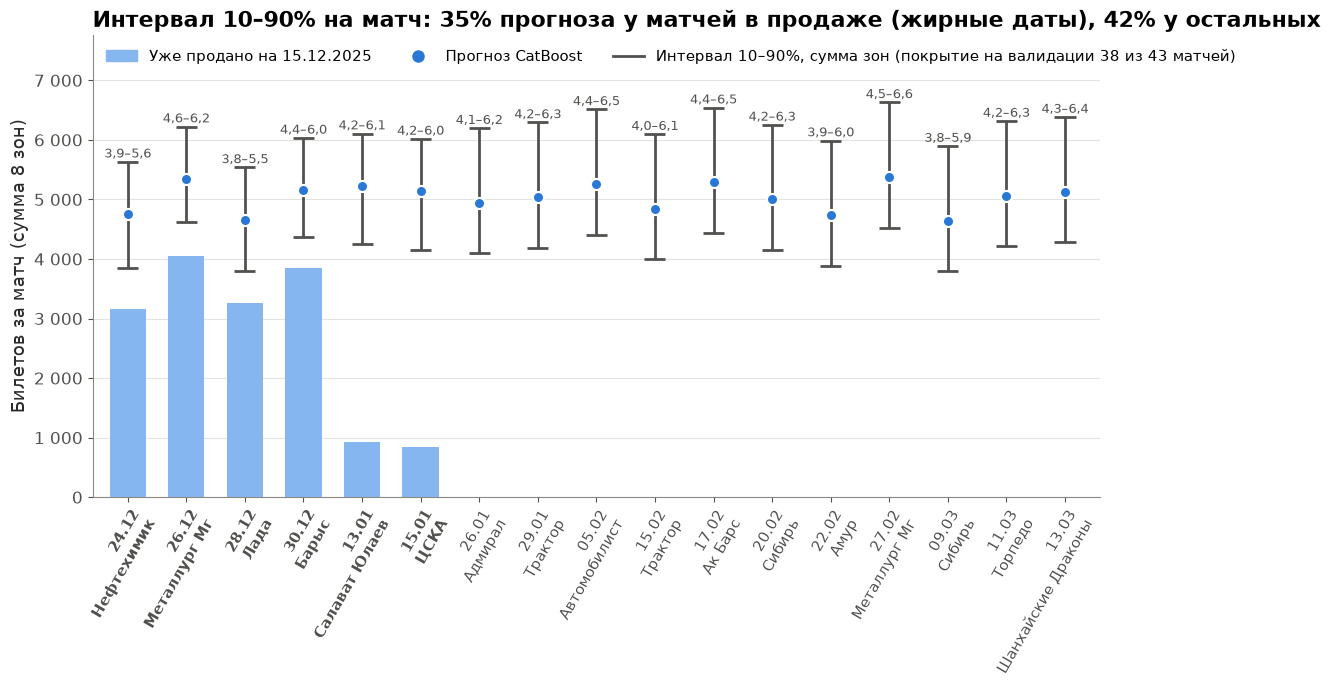

In [27]:
fig, ax = plt.subplots(figsize=(13, 6))
x = np.arange(len(tmi))
ax.bar(x, tmi["sold"], 0.62, color="#86b6ef", label="Уже продано на 15.12.2025", zorder=2)
ax.vlines(x, tmi["low"], tmi["high"], color=INK2, lw=2, zorder=3)
for cap_y in ("low", "high"):
    ax.hlines(tmi[cap_y], x - 0.18, x + 0.18, color=INK2, lw=2, zorder=3)
ax.scatter(x, tmi["pred"], s=64, color=MODEL_COLORS["catboost"], edgecolor="white", linewidth=1.5, zorder=4,
           label="Прогноз CatBoost")
for xi, lo, hi in zip(x, tmi["low"], tmi["high"]):
    ax.text(xi, hi + 70, f"{ru(lo / 1000)}–{ru(hi / 1000)}", ha="center", fontsize=9.5, color=INK2)
ax.set_xticks(x, [f"{d:%d.%m}\n{o}" for d, o in zip(tmi["match_date"], tmi["opponent"])],
              rotation=60, ha="right", rotation_mode="anchor", fontsize=11)
for lbl, s in zip(ax.get_xticklabels(), tmi["in_sale"]):
    if s:
        lbl.set_fontweight("bold")
ax.set_xlim(-0.6, len(tmi) - 0.4)
ax.set_ylim(0, tmi["high"].max() * 1.17)
ax.set_ylabel("Билетов за матч (сумма 8 зон)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: ru(v, 0)))
ax.grid(axis="x", visible=False)
w_in = ((tmi["high"] - tmi["low"]) / tmi["pred"])[tmi["in_sale"]].mean()
w_out = ((tmi["high"] - tmi["low"]) / tmi["pred"])[~tmi["in_sale"]].mean()
ax.set_title(f"Интервал 10–90% на матч: {w_in:.0%} прогноза у матчей в продаже (жирные даты), "
             f"{w_out:.0%} у остальных")
ax.legend(handles=[Patch(color="#86b6ef", label="Уже продано на 15.12.2025"),
                   Line2D([], [], marker="o", ls="", ms=8, color=MODEL_COLORS["catboost"], label="Прогноз CatBoost"),
                   Line2D([], [], color=INK2, lw=2, label=f"Интервал 10–90%, сумма зон (покрытие на валидации "
                                                         f"{COV_MATCH_SUM[0]} из {COV_MATCH_SUM[1]} матчей)")],
          loc="upper left", ncol=3, fontsize=11)
save(fig, "07_test_intervals.png")
plt.show()

### 4.5. Бизнес-метрики на валидации

Клубу важнее ошибка на матч целиком, чем на зону. Единица — матч (сумма 8 зон), 43 матча проверки:
- `RMSE_матч`, `MAE_матч` — билетов на матч;
- `ошибка_%_вмест` — среднее `|прогноз − факт| / Σ capacity` матча;
- `WAPE_матч_%` — `Σ|прогноз − факт| / Σ факт` по матчам; `WAPE_строк_%` — то же по строкам матч × зона
  (ошибки зон одного матча не взаимозачитываются, поэтому выше);
- `bias_матч` — среднее `прогноз − факт` на матч (< 0 — модель занижает). Ниже — bias по фолдам:
  поправку на смещение не вводим, если его знак меняется от сезона к сезону.

In [28]:
def biz(p):
    m = p.groupby(["fold", "match_id"], sort=False)[["y_true", "y_pred"]].sum()
    e = m["y_pred"] - m["y_true"]
    cap = mlev.set_index(["fold", "match_id"])["capacity"].reindex(m.index)
    return pd.Series({"RMSE_матч": rmse(m["y_true"], m["y_pred"]), "MAE_матч": e.abs().mean(),
                      "ошибка_%_вмест": (e.abs() / cap).mean() * 100,
                      "WAPE_матч_%": e.abs().sum() / m["y_true"].sum() * 100,
                      "WAPE_строк_%": (p["y_pred"] - p["y_true"]).abs().sum() / p["y_true"].sum() * 100,
                      "bias_матч": e.mean()})


biz_tab = pd.DataFrame({MODEL_NAMES[n]: biz(preds[n]) for n in order}).T
print(f"Средний факт на матч валидации: {mlev['y_true'].mean():.0f} билетов, "
      f"средняя вместимость (Σ capacity): {mlev['capacity'].mean():.0f}")
display(biz_tab.round(1))
cb = biz_tab.loc[MODEL_NAMES["catboost"]]
BIZ_CATBOOST = tuple(round(float(cb[c]), 1) for c in ("RMSE_матч", "MAE_матч", "ошибка_%_вмест", "WAPE_матч_%", "bias_матч"))
print("Для assert (RMSE, MAE, % вмест., WAPE, bias):", BIZ_CATBOOST)

bias_fold = pd.DataFrame({MODEL_NAMES[n]: preds[n].groupby(["fold", "match_id"], sort=False)[["y_true", "y_pred"]].sum()
                          .eval("y_pred - y_true").groupby(level="fold", sort=False).mean() for n in order}).T
print("Средний bias на матч по фолдам (прогноз − факт):")
display(bias_fold.round(0))
BIAS_FOLD_CATBOOST = tuple(int(round(v)) for v in bias_fold.loc[MODEL_NAMES["catboost"]])

Средний факт на матч валидации: 4862 билетов, средняя вместимость (Σ capacity): 7121


,RMSE_матч,MAE_матч,ошибка_%_вмест,WAPE_матч_%,WAPE_строк_%,bias_матч
Среднее по зоне (baseline),450.9,374.3,5.3,7.7,16.0,-177.6
Умный baseline,519.4,457.6,6.5,9.4,14.7,-330.4
CatBoost,447.5,377.5,5.3,7.8,13.2,-217.3


Для assert (RMSE, MAE, % вмест., WAPE, bias): (447.5, 377.5, 5.3, 7.8, -217.3)
Средний bias на матч по фолдам (прогноз − факт):


fold,2023-12-15,2024-11-25,2025-09-20
Среднее по зоне (baseline),-154.0,-4.0,-452.0
Умный baseline,-154.0,-331.0,-536.0
CatBoost,76.0,-364.0,-352.0


## Выводы для слайдов

In [29]:
# Цифры в выводах ниже взяты из этого прогона. Если модель изменится, assert укажет,
# что выводы нужно перепроверить.
KEY_NUMBERS = {"catboost": 124.7, "zone_mean": 141.0, "smart": 135.2, "pred_sum": 85631, "flags": 5,
               # бутстрэп (часть 3): средняя разница, ДИ95 низ, ДИ95 верх, повторов из 2000, где CatBoost лучше
               "boot_smart": (-10.5, -20.4, -0.1, 1953), "boot_zone_mean": (-16.4, -25.5, -7.2, 1999),
               # новогодние матчи (1.5): флагованные test-матчи окна; итог прошлых НГ, медиана по НГ-кривой
               # и прогноз модели для них — мин и макс доли capacity
               "ny_flagged": ("M087", "M088", "M089"), "ny_past_fill": (0.66, 0.72),
               "ny_curve_median": (0.56, 0.63), "ny_model": (0.73, 0.77),
               # часть 4: группы зон по вместимости; покрытие LOFO (попало, всего) — строки, матч прямой,
               # матч суммой зональных границ; сумма по 17 матчам (низ, прогноз, верх) прямого интервала;
               # бизнес-метрики на матч (RMSE, MAE, % вместимости, WAPE %, bias)
               "zone_groups": ((1, 2, 8), (3, 4, 5), (6, 7)), "cov_zone_lofo": (238, 344),
               "cov_match_direct": (26, 43), "cov_match_sum": (38, 43), "test_interval": (71033, 85631, 104668),
               "biz_catboost": (447.5, 377.5, 5.3, 7.8, -217.3), "biz_zone_mean": (450.9, 374.3, 5.3, 7.7, -177.6),
               # средний bias CatBoost на матч по трём фолдам
               "bias_fold_catboost": (76, -364, -352)}
ny_fl = ny_tab[ny_tab.index.isin(flag_table["match_id"])]
rng2 = lambda s: (round(float(s.min()), 2), round(float(s.max()), 2))
now = {"catboost": round(float(overall["catboost"]), 1), "zone_mean": round(float(overall["zone_mean"]), 1),
       "smart": round(float(overall["smart"]), 1), "pred_sum": int(test_m["pred"].sum()), "flags": len(flag_table),
       **BOOT_KEYS, "ny_flagged": tuple(ny_fl.index), "ny_past_fill": rng2(past_tab["итог_заполн"]),
       "ny_curve_median": rng2(ny_fl["по_НГ_кривой_медиана"]), "ny_model": rng2(ny_fl["прогноз_модели"]),
       "zone_groups": ZONE_GROUPS, "cov_zone_lofo": COV_ZONE, "cov_match_direct": COV_MATCH_DIRECT,
       "cov_match_sum": COV_MATCH_SUM, "test_interval": TEST_INTERVAL, "biz_catboost": BIZ_CATBOOST,
       "biz_zone_mean": tuple(round(float(biz_tab.loc[MODEL_NAMES["zone_mean"], c]), 1)
                              for c in ("RMSE_матч", "MAE_матч", "ошибка_%_вмест", "WAPE_матч_%", "bias_матч")),
       "bias_fold_catboost": BIAS_FOLD_CATBOOST}
assert now == KEY_NUMBERS, f"цифры изменились: {now} != {KEY_NUMBERS} — обновите выводы"
print("Цифры выводов актуальны:", now)
print(f"Время прогона ноутбука: {time.perf_counter() - T0:.0f} с")

Цифры выводов актуальны: {'catboost': 124.7, 'zone_mean': 141.0, 'smart': 135.2, 'pred_sum': 85631, 'flags': 5, 'boot_smart': (-10.5, -20.4, -0.1, 1953), 'boot_zone_mean': (-16.4, -25.5, -7.2, 1999), 'ny_flagged': ('M087', 'M088', 'M089'), 'ny_past_fill': (0.66, 0.72), 'ny_curve_median': (0.56, 0.63), 'ny_model': (0.73, 0.77), 'zone_groups': ((1, 2, 8), (3, 4, 5), (6, 7)), 'cov_zone_lofo': (238, 344), 'cov_match_direct': (26, 43), 'cov_match_sum': (38, 43), 'test_interval': (71033, 85631, 104668), 'biz_catboost': (447.5, 377.5, 5.3, 7.8, -217.3), 'biz_zone_mean': (450.9, 374.3, 5.3, 7.7, -177.6), 'bias_fold_catboost': (76, -364, -352)}
Время прогона ноутбука: 3 с


1. **CatBoost точнее baseline на 12%:** RMSE 124,7 билета на зону против 141,0 у среднего по зоне и 135,2 у умного baseline.
2. **CatBoost лучше baseline из задания на всех трёх датах; против умного baseline выигрыш на грани значимости** (лучше в 2 из 3 дат, ≈98% повторов бутстрэпа): умный baseline обходит его на фолде 25.11.2024 (79 против 83), 95% ДИ разницы от −20,4 до −0,1 (часть 3).
3. **Уже начавшиеся продажи — самый сильный сигнал:** на матчах в продаже ошибка 106 билетов, на ещё не открытых 132, поэтому прогноз стоит обновлять каждую неделю по свежим продажам.
4. **Основная ошибка — в массовых зонах 6 и 7** (RMSE 203 и 219 против 26–55 в зонах 1–3 и 8): спрос на самые большие дешёвые сектора колеблется сильнее всего и хуже всего объясняется календарём и соперником.
5. **На 17 оставшихся матчей прогноз — 85,6 тыс. билетов** (в среднем 5,0 тыс. за матч, на 5% выше сыгранной части сезона); ни один матч и ни одна зона не выходят за исторические пределы.
6. **Новогодние матчи 26–30.12 продаются рано, как в прошлые Новые годы** (продано уже 51–59% мест, в 1,6–2,1 раза быстрее обычного матча). Спрос приходит раньше, но не больше: прошлые новогодние матчи к той же дате были проданы на 58–68% (4 из 5) и закончили на 66–72%. В этом году к той же дате продано меньше; по новогодней кривой итог был бы 56–63%, модель ставит 73–77% — она учитывает, что сезон 2025/26 в целом заполненнее (70% против 63–66%). Аналогия построена на 5 матчах, поэтому риск отклонения в обе стороны, скорее в сторону переоценки. Прогноз модели не правили, чтобы не подгонять под 5 матчей; клубу стоит следить за остатком мест на эти матчи и обновлять прогноз по свежим продажам (раздел 1.5).
7. **На матч целиком CatBoost на уровне простого среднего: общий спрос зависит от уровня сезона.** RMSE 448 билетов на матч против 451 у среднего по зоне, MAE 378 против 374, ошибка 5,3% вместимости у обоих (часть 4.5). Выигрыш модели — в распределении спроса по зонам (WAPE по строкам 13,2% против 16,0%). Все модели в среднем занижают (CatBoost — на 217 билетов на матч), но у CatBoost знак смещения меняется от сезона к сезону (+76, −364 и −352 билета на матч по трём фолдам), поэтому поправку не вводим.
8. **Неопределённость: интервал 10–90% на матч — сумма зональных границ, на валидации он покрыл 38 из 43 матчей (88%).** Ширина — 35% прогноза у матчей в продаже и 42% у остальных; в сумме по 17 матчам границы дают 71,0–104,7 тыс. билетов при прогнозе 85,6 тыс. (`prediction_intervals_by_match.csv`, график 07). Прямой интервал по остатку суммы матча вдвое уже, но покрыл только 26 из 43 (60%): он не учитывает межсезонный сдвиг уровня спроса. Зональные интервалы (`prediction_intervals.csv`) — ориентир: на валидации покрытие 69% при номинале 80%. Клубу планировать в этом коридоре и пересматривать прогноз по свежим продажам.